# §4 Exploratory Analysis and Analytical Fallacies (Stage S4)

This section answers three questions before any model is fitted:

1. **Which weight and which variance method give population numbers we can trust?** We validate
   our survey toolkit (`src/survey.py`) against an official NCHS publication (Data Brief 516).
2. **Which descriptive contrasts are artefacts?** Unweighted vs weighted prevalence, crude vs
   age-standardised group differences, a systematic Simpson scan and a DAG that says which
   variables may be adjusted for and which must not be.
3. **What does the data structure imply for the algorithm?** Redundancy, collinearity, skewness,
   non-linearity and interactions are quantified and turned into a "data → algorithm" (DAJ) table
   that S6–S7 cite.

| § | Item | Artefact |
|---|---|---|
| 4.1 | Survey design and weights map | `results/S4/weights_map.md` |
| 4.2 | Variance engine check | – |
| 4.3 | External anchor: NCHS Data Brief 516 | `results/S4/db516_replication.csv`, `figures/S4_db516_forest.png` |
| 4.4 | Weighted vs unweighted prevalence | `figures/S4_age_structure.png` |
| 4.5 | Age standardisation | `results/S4/std_prev_table.csv` |
| 4.6 | Insurance: attenuation, not reversal | `figures/S4_crude_vs_std.png` |
| 4.7 | Simpson scan | `results/S4/simpson_scan.csv` |
| 4.8 | Causal structure (DAG) | `figures/S4_dag.png` |
| 4.9 | Redundancy and collinearity | `results/S4/vif_table.csv`, `figures/S4_spearman_clustermap.png` |
| 4.10 | Skewness | `results/S4/skew_table.csv` |
| 4.11 | Linearity | `results/S4/linearity_tests.csv`, `figures/S4_binned_logodds.png` |
| 4.12 | Interactions and power | `results/S4/interaction_tests.csv` |
| 4.13 | Data → algorithm (DAJ) table | `results/S4/daj_table.csv` |
| 4.14 | Self-check and decision register | `governance/register/S4.csv` |

All population estimates use the delete-one-PSU jackknife; every proportion carries its
domain degrees of freedom, a Korn–Graubard interval and the NCHS presentation flags.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, survey as S, labels as L

pd.set_option("display.width", 160, "display.max_columns", 30)
RNG_SEEDS = np.random.SeedSequence(C.SEED_MASTER).spawn(8)   # one child stream per random step
OUT: dict = {}            # every reported number -> results/metrics_S4.json
REG: list[dict] = []      # decision-register rows -> governance/register/S4.csv
S4_DIR = C.RESULTS_DIR / "S4"
S4_DIR.mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"


def reg(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
        check_verdict="PASS", check_note="", hyp_id="", status="final", loop_ref=""):
    """Append one decision-register row (columns per process doc §7.2)."""
    REG.append({"dr_id": dr_id, "stage": "S4", "date": TODAY, "type": type_, "finding": finding,
                "evidence_ref": evidence_ref, "evidence_value": evidence_value, "decision": decision,
                "alternatives_rejected": alternatives_rejected, "hyp_id": hyp_id, "status": status,
                "check_verdict": check_verdict, "check_note": check_note, "loop_ref": loop_ref,
                "change_request": "", "commit": ""})


def pct(x, d=1):
    return f"{100 * x:.{d}f}"


def md_table(df: pd.DataFrame) -> str:
    """Minimal Markdown table (no extra dependency)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return chr(10).join(lines)


coh = L.add_labels(io.build_cohort())
assert len(coh) == io.COHORT_N == 5730
print(f"cohort: {len(coh):,} adults, L_comb positives {int(coh.L_comb.sum())}")

cohort: 5,730 adults, L_comb positives 971


## 4.1 Survey design and weights map
**Why.** NHANES is a stratified, clustered, unequal-probability sample. Each data component was
collected on a different subsample and carries its own weight; using the wrong weight (or none)
changes the population the numbers describe. The variance must reflect the 15 masked strata ×
2 PSUs, which leaves only **15 design degrees of freedom** however many people are sampled.

In [2]:
WEIGHTS_MAP = pd.DataFrame([
    ("Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ)", C.WEIGHT_INTERVIEW, "all interviewed", "interview-only descriptives"),
    ("MEC examination (BMX, BPXO)", C.WEIGHT_MEC, "examined", "exam-only descriptives"),
    ("Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)", C.WEIGHT_PHLEB, "examined + blood drawn", "**cohort analyses (contain HbA1c)**"),
    ("Fasting analytes (GLU, TRIGLY/LDL)", C.WEIGHT_FASTING, "morning fasting subsample, 8–24 h fast", "**DB516 replication, triglycerides, LDL**"),
], columns=["component", "weight", "subsample", "used here for"])
WEIGHTS_MAP["positive in cohort"] = [int((coh[w].fillna(0) > 0).sum()) for w in WEIGHTS_MAP.weight]
print(WEIGHTS_MAP.to_string(index=False))

design = coh.groupby(C.STRATA)[C.PSU].nunique()
n_strata, n_psu = design.size, int(design.sum())
DF_DESIGN = S.design_df(coh)
print(f"\nstrata = {n_strata}, PSUs = {n_psu}, design df = #PSU - #strata = {DF_DESIGN}")
assert (n_strata, n_psu, DF_DESIGN) == (15, 30, 15)
print(f"fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the cohort: "
      f"{int(((coh.WTSAF2YR == 0)).sum())}")

rule = ("Rule: when variables from several components are combined, use the weight of the smallest "
        "subsample involved (fasting < phlebotomy < MEC < interview).")
md = ["# Weights map (S4)", "", md_table(WEIGHTS_MAP), "", rule, "",
      f"Design: {n_strata} strata x 2 PSUs = {n_psu} PSUs; design df = {DF_DESIGN}. "
      "Variance: delete-one-PSU jackknife (JKn); domains by zeroing weights; domain df = number of "
      "strata containing domain observations; df < 8 flagged as unstable (NCHS)."]
(S4_DIR / "weights_map.md").write_text("\n".join(md) + "\n", encoding="utf-8")
WEIGHTS_MAP.to_csv(S4_DIR / "weights_map.csv", index=False)
OUT["design"] = {"n_strata": n_strata, "n_psu": n_psu, "df": DF_DESIGN,
                 "n_wtph_pos": int((coh.WTPH2YR > 0).sum()),
                 "n_fasting_pos": int((coh.WTSAF2YR.fillna(0) > 0).sum())}

                                                    component   weight                              subsample                             used here for  positive in cohort
Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ) WTINT2YR                        all interviewed               interview-only descriptives                5730
                                  MEC examination (BMX, BPXO) WTMEC2YR                               examined                    exam-only descriptives                5730
                Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)  WTPH2YR                 examined + blood drawn       **cohort analyses (contain HbA1c)**                5730
                           Fasting analytes (GLU, TRIGLY/LDL) WTSAF2YR morning fasting subsample, 8–24 h fast **DB516 replication, triglycerides, LDL**                2938

strata = 15, PSUs = 30, design df = #PSU - #strata = 15
fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the co

**So what.** Every cohort row has a phlebotomy weight (`WTPH2YR` > 0), so it is the weight for all
cohort descriptives and for the weighted ablation arm; the fasting weight `WTSAF2YR` is reserved
for analyses that involve fasting glucose, triglycerides or LDL. Note that fasting participants who
did not meet the 8–24 h criterion carry `WTSAF2YR = 0` and must be excluded from fasting analyses
even though their glucose value is present (see §4.10 for the consequence). With 15 design df, a
t-quantile of 2.13 (not 1.96) applies to every full-sample interval.

## 4.2 Variance engine check
**Why.** The jackknife is the backbone of every interval in the project, so it is checked twice
before use: (a) against an independent variance method – Taylor linearisation of the ratio
estimator – and (b) on domains, where the correct approach is to zero the weights outside the
domain rather than drop rows, and where the degrees of freedom shrink to the number of strata
that contain the domain.

In [3]:
def taylor_se_ratio(df, y, weight, domain=None):
    """Taylor-linearised SE of a weighted domain mean (with-replacement PSU approximation)."""
    yv = df[y].to_numpy(float) if isinstance(y, str) else np.asarray(y, float)
    dm = np.ones(len(df), bool) if domain is None else np.asarray(domain, bool)
    w = df[weight].fillna(0).to_numpy(float) * dm * ~np.isnan(yv)
    y0 = np.nan_to_num(yv)
    p = np.dot(w, y0) / w.sum()
    z = w * (y0 - p) / w.sum()
    tot = pd.DataFrame({"h": df[C.STRATA].to_numpy(), "i": df[C.PSU].to_numpy(), "z": z}).groupby(["h", "i"]).z.sum()
    var = 0.0
    for _, g in tot.groupby(level=0):
        nh = len(g)
        var += nh / (nh - 1) * ((g - g.mean()) ** 2).sum()
    return p, np.sqrt(var)


checks = []
asian = coh.race.eq("NH Asian").to_numpy()
undx_dom = coh.L_A1c.eq(1).to_numpy()
for name, y, dom in [("L_comb, all adults", "L_comb", None),
                     ("L_comb, NH Asian", "L_comb", asian),
                     ("undiagnosed share, HbA1c>=6.5", "in_escreen", undx_dom),
                     ("undiagnosed share, Asian HbA1c>=6.5", "in_escreen", undx_dom & asian)]:
    jk = S.weighted_prop(coh, y, weight=C.WEIGHT_PHLEB, domain=dom)
    p_t, se_t = taylor_se_ratio(coh, y, C.WEIGHT_PHLEB, dom)
    checks.append({"estimate": name, "n": jk["n"], "p": jk["est"], "se_jk": jk["se"], "se_taylor": se_t,
                   "ratio": jk["se"] / se_t, "domain_df": jk["df"], "kg_low": jk["kg_low"],
                   "kg_high": jk["kg_high"], "flags": ",".join(jk["nchs_flags"]) or "–"})
checks = pd.DataFrame(checks)
print(checks.round(4).to_string(index=False))
assert np.allclose(checks.ratio, 1, atol=0.02), "jackknife and Taylor SEs disagree"

# zero-weighting vs dropping rows: identical point estimate, but dropping hides which strata are empty
drop = coh[undx_dom & asian]
print(f"\nAsian undiagnosed domain: {len(drop)} rows in {drop[C.STRATA].nunique()} strata / "
      f"{drop[[C.STRATA, C.PSU]].drop_duplicates().shape[0]} PSUs -> domain df = "
      f"{S.domain_df(coh, undx_dom & asian)} (flag df<8: {S.domain_df(coh, undx_dom & asian) < C.NCHS_MIN_DF})")
OUT["variance_check"] = checks.drop(columns="flags").to_dict("records")
OUT["asian_undx_domain_df"] = S.domain_df(coh, undx_dom & asian)

                           estimate    n      p  se_jk  se_taylor  ratio  domain_df  kg_low  kg_high                   flags
                 L_comb, all adults 5730 0.1404 0.0075     0.0075 1.0004         15  0.1247   0.1572                       –
                   L_comb, NH Asian  315 0.1161 0.0174     0.0173 1.0088         15  0.0804   0.1606                       –
      undiagnosed share, HbA1c>=6.5  721 0.2162 0.0217     0.0217 1.0001         15  0.1713   0.2666                       –
undiagnosed share, Asian HbA1c>=6.5   40 0.3621 0.0932     0.0922 1.0116          8  0.1646   0.6010 n_eff<30,ci_width>=0.30

Asian undiagnosed domain: 40 rows in 8 strata / 12 PSUs -> domain df = 8 (flag df<8: False)


**So what.** The jackknife and Taylor standard errors agree to within 2 % on the full sample and on
small domains (the ratio column), so the jackknife can be trusted for non-linear statistics where no
Taylor formula is at hand (standardised differences, κ, AUC). The Asian-undiagnosed domain lives in
only 8 strata: its df is 8, right at the NCHS instability threshold, which is why S5 reports it as
exploratory. Dropping the rows would have given the same point estimate but silently treated the
empty strata as if they did not exist in the design.

## 4.3 External anchor: NCHS Data Brief 516
**Why.** An internal check cannot detect a wrong *definition* or a wrong *weight*. Re-deriving an
official estimate from the same public files can: if our cohort logic, fasting weight, jackknife,
Korn–Graubard interval and age standardisation are all correct, we must land on NCHS Data Brief 516
(Gwira et al. 2024, Tables 1–2). DB516 definitions: adults ≥ 20, non-pregnant, fasting subsample
(`WTSAF2YR` > 0, 8–24 h fast); diagnosed = DIQ010 = 1; undiagnosed = not diagnosed and
(fasting glucose ≥ 126 mg/dL or HbA1c ≥ 6.5 %); total = diagnosed + undiagnosed; age adjustment to
the US 2000 standard with 20–39 / 40–59 / 60+. Note the fasting weight, **not** `WTPH2YR`.

In [4]:
# NCHS Data Brief 516, Tables 1-2 (external reference values, transcribed from
# https://www.cdc.gov/nchs/products/databriefs/db516.htm). Percent (95% CI).
NCHS = pd.DataFrame([
    # measure, group, kind, n, est, lo, hi
    ("total", "All", "crude", 2938, 15.8, 13.6, 18.2), ("total", "All", "age-adj", 2938, 14.3, 12.1, 16.7),
    ("total", "Men", "crude", 1306, 18.0, 15.7, 20.4), ("total", "Men", "age-adj", 1306, 16.6, 14.0, 19.4),
    ("total", "Women", "crude", 1632, 13.7, 11.0, 16.7), ("total", "Women", "age-adj", 1632, 12.2, 9.9, 14.8),
    ("diagnosed", "All", "crude", 2938, 11.3, 9.3, 13.5), ("diagnosed", "All", "age-adj", 2938, 10.1, 8.3, 12.1),
    ("diagnosed", "Men", "crude", 1306, 12.9, 11.0, 15.0), ("diagnosed", "Men", "age-adj", 1306, 11.7, 9.9, 13.7),
    ("diagnosed", "Women", "crude", 1632, 9.7, 7.3, 12.7), ("diagnosed", "Women", "age-adj", 1632, 8.6, 6.7, 10.9),
    ("undiagnosed", "All", "crude", 2938, 4.5, 3.3, 5.9), ("undiagnosed", "All", "age-adj", 2938, 4.2, 2.9, 5.7),
    ("undiagnosed", "Men", "crude", 1306, 5.1, 3.6, 6.9), ("undiagnosed", "Men", "age-adj", 1306, 4.9, 3.3, 6.9),
    ("undiagnosed", "Women", "crude", 1632, 3.9, 2.8, 5.3), ("undiagnosed", "Women", "age-adj", 1632, 3.5, 2.4, 5.1),
    ("total", "20-39", "crude", 688, 3.6, 2.0, 5.9), ("total", "40-59", "crude", 861, 17.7, 14.7, 21.0),
    ("total", "60+", "crude", 1389, 27.3, 23.0, 31.9),
    ("diagnosed", "20-39", "crude", 688, 2.2, 1.1, 4.0), ("diagnosed", "40-59", "crude", 861, 12.1, 10.0, 14.5),
    ("diagnosed", "60+", "crude", 1389, 20.5, 16.2, 25.3),
    ("undiagnosed", "20-39", "crude", 688, 1.3, 0.5, 3.0), ("undiagnosed", "40-59", "crude", 861, 5.6, 3.3, 8.9),
    ("undiagnosed", "60+", "crude", 1389, 6.8, 5.3, 8.5),
], columns=["measure", "group", "kind", "n_nchs", "nchs", "nchs_low", "nchs_high"])

fast = coh.copy()
fast_dom = (fast[C.WEIGHT_FASTING].fillna(0) > 0) & fast.LBXGLU.notna()
fast["diagnosed"] = fast.L_self.astype(float)
fast["undiagnosed"] = ((fast.L_self == 0) & ((fast.LBXGLU >= L.FPG_CUT) | (fast.LBXGH >= L.A1C_CUT))).astype(float)
fast["total"] = ((fast.diagnosed == 1) | (fast.undiagnosed == 1)).astype(float)
fast["All"] = "All"
fast["age3"] = S.age_band(fast.RIDAGEYR).to_numpy()
fast["sexg"] = fast.sex.map({"Male": "Men", "Female": "Women"})
# the SL5 label of labels.py is the same NCHS definition - cross-check
assert (L.sensitivity_labels(fast)["SL5"][fast_dom] == fast.loc[fast_dom, "total"]).all()

rows = []
for measure in ["total", "diagnosed", "undiagnosed"]:
    for gcol in ["All", "sexg"]:
        t = S.age_standardise(fast, measure, gcol, weight=C.WEIGHT_FASTING, domain=fast_dom)
        for _, r in t.iterrows():
            rows.append((measure, r.group, "crude", r.n, r.crude, r.crude_kg_low, r.crude_kg_high, r.crude_low, r.crude_high, r.df))
            rows.append((measure, r.group, "age-adj", r.n, r["std"], r.std_kg_low, r.std_kg_high, r.std_low, r.std_high, r.df))
    for band in ["20-39", "40-59", "60+"]:
        r = S.weighted_prop(fast, measure, weight=C.WEIGHT_FASTING, domain=fast_dom & (fast.age3 == band))
        rows.append((measure, band, "crude", r["n"], r["est"], r["kg_low"], r["kg_high"], r["ci_low"], r["ci_high"], r["df"]))
ours = pd.DataFrame(rows, columns=["measure", "group", "kind", "n", "est", "kg_low", "kg_high", "jk_low", "jk_high", "df"])
ours[["est", "kg_low", "kg_high", "jk_low", "jk_high"]] *= 100
DB516 = NCHS.merge(ours, on=["measure", "group", "kind"], how="left")
DB516["diff_pp"] = DB516.est - DB516.nchs
DB516["ci_overlap"] = (DB516.kg_low <= DB516.nchs_high) & (DB516.kg_high >= DB516.nchs_low)
DB516["kg_matches_nchs_ci"] = ((DB516.kg_low.round(1) - DB516.nchs_low).abs() <= 0.1) & \
                              ((DB516.kg_high.round(1) - DB516.nchs_high).abs() <= 0.1)
DB516.to_csv(S4_DIR / "db516_replication.csv", index=False)
print(DB516[["measure", "group", "kind", "n", "n_nchs", "est", "kg_low", "kg_high", "nchs", "nchs_low",
             "nchs_high", "diff_pp"]].round(2).to_string(index=False))

assert (DB516.n == DB516.n_nchs).all(), "sample sizes differ from NCHS"
assert DB516.diff_pp.abs().max() <= 0.1 + 1e-9 and DB516.ci_overlap.all()
head = DB516.query("group == 'All'").set_index(["measure", "kind"])
print(f"\nheadline: total {head.loc[('total','crude'),'est']:.2f}% "
      f"(JK t15 {head.loc[('total','crude'),'jk_low']:.2f}, {head.loc[('total','crude'),'jk_high']:.2f}; "
      f"KG {head.loc[('total','crude'),'kg_low']:.2f}, {head.loc[('total','crude'),'kg_high']:.2f}); "
      f"diagnosed {head.loc[('diagnosed','crude'),'est']:.2f}; undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f}; "
      f"age-adjusted {head.loc[('total','age-adj'),'est']:.2f}/{head.loc[('diagnosed','age-adj'),'est']:.2f}/"
      f"{head.loc[('undiagnosed','age-adj'),'est']:.2f}")
print(f"max |diff| over {len(DB516)} published estimates = {DB516.diff_pp.abs().max():.3f} pp; "
      f"KG interval equals the published CI (to 0.1 pp) in {int(DB516.kg_matches_nchs_ci.sum())}/{len(DB516)} rows")

    measure group    kind    n  n_nchs   est  kg_low  kg_high  nchs  nchs_low  nchs_high  diff_pp
      total   All   crude 2938    2938 15.79   13.59    18.19  15.8      13.6       18.2    -0.01
      total   All age-adj 2938    2938 14.31   12.21    16.62  14.3      12.1       16.7     0.01
      total   Men   crude 1306    1306 17.97   15.69    20.43  18.0      15.7       20.4    -0.03
      total   Men age-adj 1306    1306 16.57   14.05    19.34  16.6      14.0       19.4    -0.03
      total Women   crude 1632    1632 13.66   10.99    16.69  13.7      11.0       16.7    -0.04
      total Women age-adj 1632    1632 12.16    9.95    14.67  12.2       9.9       14.8    -0.04
  diagnosed   All   crude 2938    2938 11.30    9.31    13.55  11.3       9.3       13.5    -0.00
  diagnosed   All age-adj 2938    2938 10.13    8.42    12.05  10.1       8.3       12.1     0.03
  diagnosed   Men   crude 1306    1306 12.90   10.98    15.02  12.9      11.0       15.0     0.00
  diagnosed   Men ag

The process document quotes 15.78 / 11.29 / 4.48 on *n* = 2,940. That variant keeps two fasting
adults without an HbA1c result (counted as non-diabetic); NCHS's *n* = 2,938 excludes them. The next
cell reproduces both so the 0.01 pp difference is explained rather than hidden.

In [5]:
full = io.zero_weights_to_nan(io.load_merged())
v_dom = (full.RIDAGEYR >= C.ADULT_MIN_AGE) & (full.RIDEXPRG != 1) & (full[C.WEIGHT_FASTING].fillna(0) > 0)
dx = full.DIQ010.eq(1)
und = ~dx & (full.LBXGLU.ge(L.FPG_CUT) | full.LBXGH.ge(L.A1C_CUT))
variant = {}
for nm, y in [("total", dx | und), ("diagnosed", dx), ("undiagnosed", und)]:
    r = S.weighted_prop(full, y.astype(float), weight=C.WEIGHT_FASTING, domain=v_dom)
    variant[nm] = {"n": r["n"], "est": 100 * r["est"], "jk_low": 100 * r["ci_low"], "jk_high": 100 * r["ci_high"]}
print(pd.DataFrame(variant).T.round(2))
print("rows in the 2,940 variant without HbA1c:", int((v_dom & full.LBXGH.isna()).sum()))

OUT["db516"] = {"n": int(head.loc[("total", "crude"), "n"]),
                "total": head.loc[("total", "crude"), "est"], "total_jk_ci": [head.loc[("total", "crude"), "jk_low"], head.loc[("total", "crude"), "jk_high"]],
                "total_kg_ci": [head.loc[("total", "crude"), "kg_low"], head.loc[("total", "crude"), "kg_high"]],
                "diagnosed": head.loc[("diagnosed", "crude"), "est"], "undiagnosed": head.loc[("undiagnosed", "crude"), "est"],
                "age_adj": [head.loc[(m, "age-adj"), "est"] for m in ["total", "diagnosed", "undiagnosed"]],
                "max_abs_diff_pp": DB516.diff_pp.abs().max(), "n_estimates": len(DB516),
                "kg_matches_published_ci": int(DB516.kg_matches_nchs_ci.sum()),
                "variant_n2940": variant}

                  n    est  jk_low  jk_high
total        2940.0  15.78   13.53    18.03
diagnosed    2940.0  11.29    9.23    13.36
undiagnosed  2940.0   4.48    3.26     5.71
rows in the 2,940 variant without HbA1c: 2


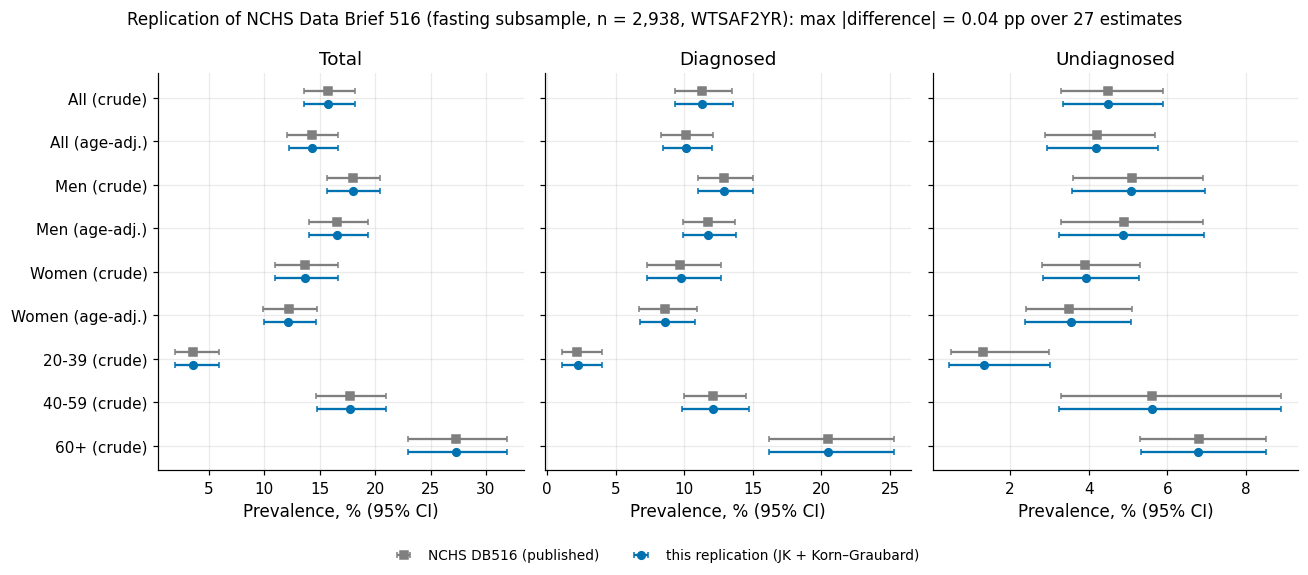

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.2), sharey=True)
for ax, measure in zip(axes, ["total", "diagnosed", "undiagnosed"]):
    d = DB516[DB516.measure == measure].reset_index(drop=True)
    labels_ = [f"{g} ({'age-adj.' if k == 'age-adj' else 'crude'})" for g, k in zip(d.group, d.kind)]
    yy = np.arange(len(d))[::-1]
    ax.errorbar(d.nchs, yy + 0.15, xerr=[d.nchs - d.nchs_low, d.nchs_high - d.nchs], fmt="s", ms=5,
                color=C.OKABE_ITO["grey"], capsize=2, label="NCHS DB516 (published)")
    ax.errorbar(d.est, yy - 0.15, xerr=[d.est - d.kg_low, d.kg_high - d.est], fmt="o", ms=5,
                color=C.OKABE_ITO["blue"], capsize=2, label="this replication (JK + Korn–Graubard)")
    ax.set_yticks(yy, labels_)
    ax.set_title(measure.capitalize())
    ax.set_xlabel("Prevalence, % (95% CI)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, fontsize=9)
fig.suptitle(f"Replication of NCHS Data Brief 516 (fasting subsample, n = 2,938, WTSAF2YR): "
             f"max |difference| = {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plots.savefig(fig, "S4_db516_forest",
              caption="Our design-based estimates (blue, Korn-Graubard 95% CI) against the published NCHS "
                      "Data Brief 516 values (grey) for total, diagnosed and undiagnosed diabetes, crude and "
                      "age-adjusted, overall, by sex and by age group.")
plt.show()

reg("DR-S4-01", "method", "NHANES 2021-23 has 15 strata x 2 PSUs (df = 15); every cohort row has WTPH2YR > 0; "
    "jackknife SE agrees with Taylor linearisation (ratio within 2%).",
    "results/S4/weights_map.md; §4.2", f"df = {DF_DESIGN}; JK/Taylor SE ratio {checks.ratio.min():.3f}-{checks.ratio.max():.3f}",
    "WTPH2YR for all cohort analyses and the weighted ablation; WTSAF2YR for fasting analytes and DB516; "
    "delete-one-PSU jackknife with domain df = strata containing the domain; NCHS flags (n, n_eff < 30, "
    "KG width >= 0.30, df < 8).",
    "Unweighted analysis (describes the sample, not the population); WTMEC2YR for HbA1c (ignores blood-draw "
    "non-response); Taylor-only variance (no formula for kappa/AUC/standardised differences).",
    check_note="re-computed in §4.2")
reg("DR-S4-02", "validation", "Survey toolkit reproduces NCHS Data Brief 516 on the fasting subsample.",
    "results/S4/db516_replication.csv; figures/S4_db516_forest.png",
    f"total {head.loc[('total','crude'),'est']:.2f}% vs 15.8; diagnosed {head.loc[('diagnosed','crude'),'est']:.2f} vs 11.3; "
    f"undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f} vs 4.5; max |diff| {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates",
    "Use src/survey.py (JK + KG + 3-band US 2000 standardisation) for every population number in S4-S9.",
    "Accept the toolkit on internal checks only (cannot detect wrong definitions or weights).",
    check_note=f"n = 2,938 equals NCHS; the process-doc figure 15.78 comes from an n = 2,940 variant with 2 missing HbA1c")

**So what.** All 27 published DB516 estimates (overall, by sex, by age; crude and age-adjusted) are
reproduced within 0.1 pp, with exactly NCHS's sample size of 2,938, and our Korn–Graubard intervals
coincide with the published asymmetric intervals – evidence that NCHS itself uses the KG interval
and that our cohort filter, fasting weight, jackknife and standardisation are right. The symmetric
jackknife-*t* interval for the total (13.53, 18.03) is the Wald version of the same uncertainty.
This is the external anchor for every weighted number later in the project.

## 4.4 Weighted vs unweighted prevalence
**Why.** The cohort's raw share of `L_comb` positives describes the *sample*, which over-represents
older adults. Because NCHS used a different definition (fasting glucose as well), our cohort number
is also not expected to equal DB516's 15.8 %. Both gaps need to be explained, not ignored.

In [7]:
w_ph = coh[C.WEIGHT_PHLEB].to_numpy(float)
unw = coh.L_comb.mean()
wp = S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB)
kish = S.kish_deff(w_ph)
coh["age3"] = S.age_band(coh.RIDAGEYR).to_numpy()
bands = list(S.US2000_3BAND)
share_s = coh.age3.value_counts(normalize=True).reindex(bands)
share_w = pd.Series({b: w_ph[coh.age3 == b].sum() / w_ph.sum() for b in bands})
rate_unw = coh.groupby("age3").L_comb.mean().reindex(bands)
rate_w = {b: S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB, domain=coh.age3 == b) for b in bands}
unw_age_reweighted = float((rate_unw * share_w).sum())     # sample rates, population age mix
explained = (unw - unw_age_reweighted) / (unw - wp["est"])
AGE_TAB = pd.DataFrame({"sample share": share_s, "weighted share": share_w, "unweighted rate": rate_unw,
                        "weighted rate": [rate_w[b]["est"] for b in bands],
                        "kg_low": [rate_w[b]["kg_low"] for b in bands], "kg_high": [rate_w[b]["kg_high"] for b in bands]})
print((AGE_TAB * 100).round(1))
print(f"\nL_comb unweighted {pct(unw, 2)}% vs WTPH2YR-weighted {pct(wp['est'], 2)}% "
      f"(JK {pct(wp['ci_low'])}-{pct(wp['ci_high'])}, KG {pct(wp['kg_low'])}-{pct(wp['kg_high'])}, df {wp['df']})")
print(f"sample rates re-weighted to the population age mix: {pct(unw_age_reweighted, 2)}% -> age structure explains "
      f"{100 * explained:.0f}% of the {100 * (unw - wp['est']):.2f} pp gap")
print(f"Kish deff (unequal weights) = {kish:.3f}; Kish n_eff = {S.kish_neff(w_ph):,.0f}; "
      f"full design effect for L_comb = {wp['deff']:.2f}")
assert abs(unw - 0.1695) < 5e-4 and abs(wp["est"] - 0.140) < 5e-4 and abs(kish - 1.55) < 0.01
OUT["prevalence"] = {"unweighted": unw, "weighted": wp["est"], "weighted_jk_ci": [wp["ci_low"], wp["ci_high"]],
                     "weighted_kg_ci": [wp["kg_low"], wp["kg_high"]], "kish_deff": kish, "design_deff": wp["deff"],
                     "share_60plus_sample": share_s["60+"], "share_60plus_weighted": share_w["60+"],
                     "share_20_39_sample": share_s["20-39"], "share_20_39_weighted": share_w["20-39"],
                     "unweighted_age_reweighted": unw_age_reweighted, "gap_explained_by_age": explained}

       sample share  weighted share  unweighted rate  weighted rate  kg_low  kg_high
20-39          24.7            34.8              3.7            3.5     2.6      4.8
40-59          29.2            33.8             16.6           15.3    13.4     17.5
60+            46.2            31.4             24.3           24.3    21.2     27.6

L_comb unweighted 16.95% vs WTPH2YR-weighted 14.04% (JK 12.4-15.6, KG 12.5-15.7, df 15)
sample rates re-weighted to the population age mix: 14.50% -> age structure explains 84% of the 2.91 pp gap
Kish deff (unequal weights) = 1.546; Kish n_eff = 3,707; full design effect for L_comb = 2.67


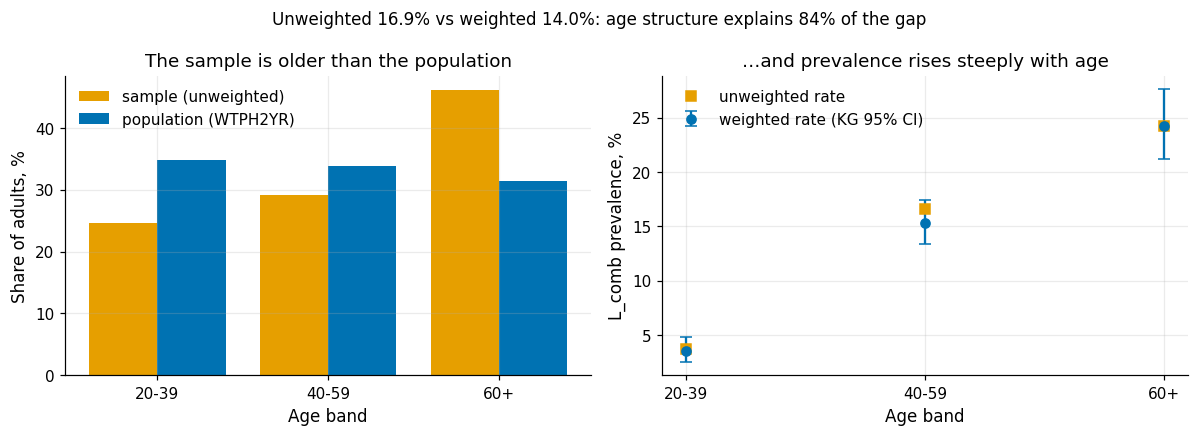

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
a1.bar(x - 0.2, share_s * 100, 0.4, label="sample (unweighted)", color=C.OKABE_ITO["orange"])
a1.bar(x + 0.2, share_w * 100, 0.4, label="population (WTPH2YR)", color=C.OKABE_ITO["blue"])
a1.set_xticks(x, bands); a1.set_ylabel("Share of adults, %"); a1.set_xlabel("Age band")
a1.set_title("The sample is older than the population"); a1.legend()
yr = AGE_TAB["weighted rate"] * 100
a2.errorbar(x, yr, yerr=[yr - AGE_TAB.kg_low * 100, AGE_TAB.kg_high * 100 - yr], fmt="o", capsize=4,
            color=C.OKABE_ITO["blue"], label="weighted rate (KG 95% CI)")
a2.plot(x, AGE_TAB["unweighted rate"] * 100, "s", color=C.OKABE_ITO["orange"], label="unweighted rate")
a2.set_xticks(x, bands); a2.set_ylabel("L_comb prevalence, %"); a2.set_xlabel("Age band")
a2.set_title("…and prevalence rises steeply with age"); a2.legend()
fig.suptitle(f"Unweighted {pct(unw)}% vs weighted {pct(wp['est'])}%: age structure explains "
             f"{100 * explained:.0f}% of the gap", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S4_age_structure",
              caption="Left: age distribution of the cohort vs the weighted population. Right: L_comb prevalence "
                      "by age band (weighted with Korn-Graubard CI, and unweighted).")
plt.show()

**So what.** 46 % of the cohort is 60+ against 31 % of the population, and prevalence in that band
is about seven times that of 20–39-year-olds, so the unweighted 16.95 % overstates the population
prevalence of 14.0 % (12.4–15.6). Re-weighting the sample's own age-specific rates to the population
age mix closes most of the gap, i.e. the bias is mainly an age-structure effect. The remaining
difference to DB516's 15.8 % is definitional (our cohort label has no fasting-glucose criterion,
and uses the phlebotomy not the fasting sample) – not an error. The Kish design effect of 1.55 means
5,730 unequally weighted adults carry the information of about 3,700 equally weighted ones; the full
design effect including clustering is larger still, which is why all CIs use the jackknife. For
modelling, this motivates the weighted ablation arm (block B6) rather than silently ignoring weights.

## 4.5 Age standardisation
**Why.** Groups with different age structures cannot be compared on crude prevalence, because age
is the strongest determinant of diabetes. Direct standardisation applies each group's age-specific
rates to one common age distribution. We use the US 2000 standard population in the three NCHS
bands; the band weights are derived here from the 5-year "standard million" (Klein & Schoenborn
2001) rather than taken on trust, and a 6-band standard and an internal (cohort) standard are
sensitivity analyses.

In [9]:
# US 2000 standard population per million, 5-year groups from age 20 (Klein & Schoenborn 2001, Table 2)
US2000_5Y = {"20-24": 66478, "25-29": 64529, "30-34": 71044, "35-39": 80762, "40-44": 81851, "45-49": 72118,
             "50-54": 62716, "55-59": 48454, "60-64": 38793, "65-69": 34264, "70-74": 31773, "75-79": 26999,
             "80-84": 17842, "85+": 15508}
lo_of = {k: int(k.rstrip("+").split("-")[0]) for k in US2000_5Y}
def collapse(cuts):
    out = {}
    for lab, (lo, hi) in cuts.items():
        out[lab] = sum(v for k, v in US2000_5Y.items() if lo <= lo_of[k] <= hi)
    tot = sum(out.values())
    return {k: v / tot for k, v in out.items()}
STD3 = collapse({"20-39": (20, 39), "40-59": (40, 59), "60+": (60, 200)})
STD6 = collapse({"20-29": (20, 29), "30-39": (30, 39), "40-49": (40, 49), "50-59": (50, 59), "60-69": (60, 69), "70+": (70, 200)})
print("3-band weights derived:", {k: round(v, 4) for k, v in STD3.items()}, "| survey.US2000_3BAND:", S.US2000_3BAND)
assert all(abs(STD3[k] - S.US2000_3BAND[k]) < 1e-4 for k in STD3)
STD_INT = {b: float(share_w[b]) for b in bands}            # internal standard: the weighted cohort itself
print("6-band weights:", {k: round(v, 4) for k, v in STD6.items()})

coh["insurance"] = coh.HIQ011.map({1: "insured", 2: "uninsured"})
coh["usual_care"] = coh.HUQ030.map({1: "has usual place", 3: "has usual place", 2: "no usual place"})
std_tabs = []
for gcol in ["race", "sex", "insurance", "usual_care"]:
    t = S.age_standardise(coh, "L_comb", gcol, weight=C.WEIGHT_PHLEB)
    t.insert(0, "grouping", gcol)
    std_tabs.append(t)
STD_TAB = pd.concat(std_tabs, ignore_index=True)
STD_TAB["kg_width"] = STD_TAB.crude_kg_high - STD_TAB.crude_kg_low
STD_TAB["nchs_flags"] = [",".join(S.nchs_flags(r.n, S._design_neff(r.crude, r.crude_se, r.n), r.kg_width, r.df)) or ""
                         for r in STD_TAB.itertuples()]
STD_TAB.to_csv(S4_DIR / "std_prev_table.csv", index=False)
show = STD_TAB[["grouping", "group", "n", "df", "crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high", "nchs_flags"]].copy()
show[["crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high"]] *= 100
print(show.round(1).to_string(index=False))

3-band weights derived: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316} | survey.US2000_3BAND: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316}
6-band weights: {'20-29': 0.1837, '30-39': 0.2129, '40-49': 0.2159, '50-59': 0.1559, '60-69': 0.1024, '70+': 0.1292}


  grouping            group    n  df  crude  crude_kg_low  crude_kg_high  std  std_low  std_high nchs_flags
      race Mexican American  386  15   16.9          11.2           24.0 19.6     14.7      24.5           
      race         NH Asian  315  15   11.6           8.0           16.1 12.5      8.2      16.7           
      race         NH Black  676  15   22.0          18.6           25.8 21.5     18.0      25.1           
      race         NH White 3408  15   12.4          10.5           14.5 10.3      8.7      12.0           
      race   Other Hispanic  582  15   12.8           7.8           19.4 13.5      9.5      17.6           
      race      Other/Multi  363  15   16.6          12.6           21.2 16.0     12.1      19.8           
       sex           Female 3144  15   13.1          10.6           15.8 11.6      9.6      13.7           
       sex             Male 2586  15   15.0          13.5           16.7 13.9     12.4      15.5           
 insurance          insured 

In [10]:
CONTRASTS = [("race", "NH Asian", "NH White"), ("race", "NH Black", "NH White"),
             ("race", "Mexican American", "NH White"), ("insurance", "insured", "uninsured"),
             ("usual_care", "has usual place", "no usual place")]
diffs = []
for gcol, a, b in CONTRASTS:
    for sname, std in [("US2000 3-band", STD3), ("US2000 6-band", STD6), ("internal 3-band", STD_INT)]:
        d = S.std_difference(coh, "L_comb", gcol, a, b, weight=C.WEIGHT_PHLEB, std=std)
        diffs.append({"contrast": f"{a} − {b}", "standard": sname, "n_a": d["n_a"], "n_b": d["n_b"], "df": d["df"],
                      "crude": 100 * d["crude_diff"], "crude_low": 100 * d["crude_low"], "crude_high": 100 * d["crude_high"],
                      "std": 100 * d["std_diff"], "std_low": 100 * d["std_low"], "std_high": 100 * d["std_high"]})
DIFFS = pd.DataFrame(diffs)
DIFFS.to_csv(S4_DIR / "std_differences.csv", index=False)
print(DIFFS.round(1).to_string(index=False))

aw = DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 3-band'").iloc[0]
iu = DIFFS.query("contrast == 'insured − uninsured' and standard == 'US2000 3-band'").iloc[0]
assert abs(aw.crude - (-0.8)) < 0.1 and abs(aw["std"] - 2.1) < 0.1 and abs(aw.crude_low + 5.1) < 0.1 and abs(aw.std_high - 6.8) < 0.1
assert abs(iu.crude - 5.3) < 0.1 and abs(iu["std"] - 0.7) < 0.1 and abs(iu.crude_low - 1.8) < 0.1 and abs(iu.std_high - 3.9) < 0.1
asian_std = STD_TAB.query("group == 'NH Asian'").iloc[0]; white_std = STD_TAB.query("group == 'NH White'").iloc[0]
print(f"\nNH Asian vs NH White: crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}) -> "
      f"standardised {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}) pp; standardised rates "
      f"{pct(asian_std['std'])}% vs {pct(white_std['std'])}% (README claim 18.0% vs 13.6% not reproducible)")
OUT["standardisation"] = {
    "std3": STD3, "std6": STD6,
    "asian_white": {"crude": aw.crude, "crude_ci": [aw.crude_low, aw.crude_high], "std": aw["std"], "std_ci": [aw.std_low, aw.std_high],
                    "std_rate_asian": 100 * asian_std["std"], "std_rate_white": 100 * white_std["std"],
                    "std6": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 6-band'")["std"].item(),
                    "internal": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'internal 3-band'")["std"].item()},
    "insured_uninsured": {"crude": iu.crude, "crude_ci": [iu.crude_low, iu.crude_high], "std": iu["std"], "std_ci": [iu.std_low, iu.std_high]}}

                        contrast        standard  n_a  n_b  df  crude  crude_low  crude_high  std  std_low  std_high
             NH Asian − NH White   US2000 3-band  315 3408  15   -0.8       -5.1         3.5  2.1     -2.6       6.8
             NH Asian − NH White   US2000 6-band  315 3408  15   -0.8       -5.1         3.5  2.3     -2.2       6.9
             NH Asian − NH White internal 3-band  315 3408  15   -0.8       -5.1         3.5  2.9     -1.7       7.5
             NH Black − NH White   US2000 3-band  676 3408  15    9.6        5.2        14.0 11.2      7.1      15.3
             NH Black − NH White   US2000 6-band  676 3408  15    9.6        5.2        14.0 10.8      6.3      15.2
             NH Black − NH White internal 3-band  676 3408  15    9.6        5.2        14.0 11.4      6.9      15.9
     Mexican American − NH White   US2000 3-band  386 3408  15    4.5       -2.4        11.3  9.3      3.6      15.0
     Mexican American − NH White   US2000 6-band  386 3408  15  

**So what.** The derived band weights match 0.3966 / 0.3718 / 0.2316 exactly, which settles the
open verification item of the process document. NH Asian adults have a slightly *lower* crude
prevalence than NH White adults (−0.8 pp, −5.1 to 3.5) but, being much younger, a *higher*
age-standardised one (+2.1 pp, −2.6 to 6.8). Both intervals include zero and the 6-band and
internal standards tell the same story, so the honest statement is "direction flips after age
standardisation, magnitude unknown" – a demonstration of honest uncertainty, not a headline. The
README's 18.0 % vs 13.6 % cannot be reproduced with any of the three standards and is withdrawn.

## 4.6 Insurance: attenuation, not reversal
**Why.** Insured adults show a clearly higher crude prevalence than uninsured adults. Before
reading this as a health-care effect we need to know how much of it is age: almost everyone
aged 65+ has Medicare, so insurance is a strong marker of age (Age → Medicare → Insurance), and
age drives diabetes.

In [11]:
ins_age = (pd.crosstab(coh.insurance, coh.age3, values=w_ph, aggfunc="sum", normalize="index") * 100).reindex(columns=bands)
print("weighted age mix by insurance status (%):\n", ins_age.round(1))
band_diff = []
for b in bands:
    d = S.std_difference(coh, "L_comb", "insurance", "insured", "uninsured", weight=C.WEIGHT_PHLEB,
                         domain=coh.age3 == b)
    band_diff.append({"age band": b, "n_insured": d["n_a"], "n_uninsured": d["n_b"],
                      "diff_pp": 100 * d["crude_diff"], "low": 100 * d["crude_low"], "high": 100 * d["crude_high"]})
band_diff = pd.DataFrame(band_diff)
print("\nage-specific insured − uninsured differences (pp):\n", band_diff.round(1).to_string(index=False))
print(f"\ninsured − uninsured: crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}) -> "
      f"age-standardised {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}) pp; "
      f"{100 * (1 - iu['std'] / iu.crude):.0f}% attenuation, same sign")
OUT["standardisation"]["insured_uninsured"].update({
    "attenuation_share": 1 - iu["std"] / iu.crude,
    "uninsured_share_60plus": ins_age.loc["uninsured", "60+"], "insured_share_60plus": ins_age.loc["insured", "60+"],
    "band_diffs": band_diff.to_dict("records")})

weighted age mix by insurance status (%):
 age3       20-39  40-59   60+
insurance                    
insured     33.4   33.0  33.7
uninsured   47.8   42.1  10.0

age-specific insured − uninsured differences (pp):
 age band  n_insured  n_uninsured  diff_pp   low  high
   20-39       1223          186     -0.7  -4.5   3.2
   40-59       1467          202      5.7   1.4  10.0
     60+       2557           86     -5.1 -12.9   2.8

insured − uninsured: crude +5.3 (1.8, 8.8) -> age-standardised +0.7 (-2.6, 3.9) pp; 87% attenuation, same sign


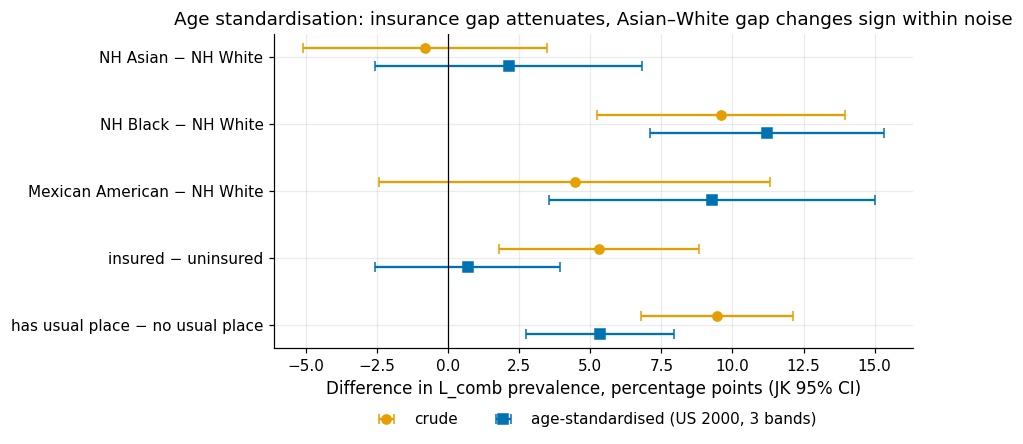

In [12]:
d3 = DIFFS[DIFFS.standard == "US2000 3-band"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
yy = np.arange(len(d3))[::-1]
ax.errorbar(d3.crude, yy + 0.13, xerr=[d3.crude - d3.crude_low, d3.crude_high - d3.crude], fmt="o", capsize=3,
            color=C.OKABE_ITO["orange"], label="crude")
ax.errorbar(d3["std"], yy - 0.13, xerr=[d3["std"] - d3.std_low, d3.std_high - d3["std"]], fmt="s", capsize=3,
            color=C.OKABE_ITO["blue"], label="age-standardised (US 2000, 3 bands)")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy, d3.contrast)
ax.set_xlabel("Difference in L_comb prevalence, percentage points (JK 95% CI)")
ax.set_title("Age standardisation: insurance gap attenuates, Asian–White gap changes sign within noise")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
plots.savefig(fig, "S4_crude_vs_std",
              caption="Crude and age-standardised prevalence differences (WTPH2YR, jackknife 95% CI, df = 15).")
plt.show()

reg("DR-S4-03", "method", "US 2000 standard collapsed to 20-39/40-59/60+ = 0.3966/0.3718/0.2316, re-derived from the 5-year standard million.",
    "results/S4/std_prev_table.csv; §4.5", "derived weights equal survey.US2000_3BAND to 1e-4",
    "Direct age standardisation (3-band US 2000) for every between-group prevalence comparison; 6-band and internal standards as sensitivity.",
    "Crude comparisons (confounded by age); internal-only standard (not comparable with NCHS).",
    check_note="re-derived in-notebook; also validated indirectly by the DB516 age-adjusted replication")
reg("DR-S4-04", "claim_change", "NH Asian vs NH White L_comb: crude -0.8 pp (-5.1, 3.5) -> standardised +2.1 pp (-2.6, 6.8); README 18.0% vs 13.6% not reproducible.",
    "results/S4/std_differences.csv; figures/S4_crude_vs_std.png",
    f"crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}); std {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}); std rates {pct(asian_std['std'])} vs {pct(white_std['std'])}%",
    "Withdraw the README 18.0/13.6 claim; report the Asian-White contrast only as an example of honest uncertainty (both CIs include 0).",
    "Headline 'Asians have higher diabetes prevalence' (not supported by the CI).",
    check_verdict="PASS-FIX", check_note="README figure corrected; numbers re-computed with three standards")
reg("DR-S4-05", "interpretation", "Insured - uninsured L_comb: crude +5.3 pp (1.8, 8.8) -> age-standardised +0.7 pp (-2.6, 3.9).",
    "results/S4/std_differences.csv; §4.6",
    f"crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}); std {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}); uninsured 60+ share {ins_age.loc['uninsured','60+']:.1f}% vs insured {ins_age.loc['insured','60+']:.1f}%",
    "Describe as age confounding (Age -> Medicare -> Insurance; Age -> diabetes) causing attenuation; never call it a reversal or Simpson's paradox.",
    "'Insurance reversal' wording of the first draft (sign does not flip).",
    check_verdict="PASS-FIX", check_note="wording corrected from 'reversal' to 'attenuation'")

**So what.** Only 10 % of uninsured adults are 60+, against a third of insured adults, because
Medicare covers almost everyone over 65. Standardising to the US 2000 age mix shrinks the gap from
+5.3 pp (1.8–8.8) to +0.7 pp (−2.6–3.9), an attenuation of almost 90 % with the **same sign**: this
is age confounding, not a Simpson reversal. The age-specific differences are heterogeneous
(about −1, +6 and −5 pp in the three bands, only the 40–59 one excluding zero), so no single
"insurance effect" summarises them; the 6-band standard gives a very wide interval because few
uninsured adults are 70+. By contrast, the *usual place of care* gap survives standardisation
(+9.4 → +5.3 pp, CI excluding zero) – consistent with a detection pathway (care → diagnosis →
self-reported diabetes) that S5 examines through the undiagnosed share. For modelling, access
features must be read conditional on age, and fairness comparisons across insurance groups (S8)
must control for age before attributing differences to access to care.

## 4.7 Simpson scan
**Why.** §4.5–4.6 examined two contrasts chosen in advance. A systematic scan asks the general
question: across all exposure × outcome × stratifier combinations, how often does stratification
change the *sign* of a weighted difference (Simpson's paradox) or shrink it by more than half?
The scan is exploratory and suffers from multiple comparisons, so (a) every row carries a
jackknife CI, (b) sign flips get a design-based bootstrap probability, and (c) only flips that the
DAG (§4.8) supports as de-confounding – stratifier is a confounder, not a mediator – may become
claims.

Grid (fixed before looking at the results): 9 binary exposures × 4 outcomes × 7 stratifiers, minus
the combinations where the stratifier *is* the exposure variable. Difference = exposure − reference,
WTPH2YR; standardised difference uses the pooled weighted stratum shares of the comparison domain
(internal standard). Flip: crude and standardised differences of opposite sign, both |Δ| > 1 pp.
Attenuation: same sign, |crude| > 1 pp and |standardised| < ½ |crude|.

In [13]:
r3 = coh.RIDRETH3
EXPOSURES = {   # name: (indicator with NaN outside the comparison, reference description)
    "female": (coh.sex.map({"Female": 1.0, "Male": 0.0}), "male"),
    "asian": (pd.Series(np.select([r3 == 6, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "black": (pd.Series(np.select([r3 == 4, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "hispanic": (pd.Series(np.select([r3.isin([1, 2]), r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "uninsured": (coh.HIQ011.map({2: 1.0, 1: 0.0}), "insured"),
    "no_usual_care": (coh.HUQ030.map({2: 1.0, 1: 0.0, 3: 0.0}), "has usual place"),
    "low_income": (pd.Series(np.where(coh.INDFMPIR.isna(), np.nan, (coh.INDFMPIR < 1.3).astype(float))), "PIR >= 1.3"),
    "ever_smoker": (coh.SMQ020.map({1: 1.0, 2: 0.0}), "never smoker"),
    "low_education": (coh.DMDEDUC2.map({1: 1.0, 2: 1.0, 3: 0.0, 4: 0.0, 5: 0.0}), "high school or more"),
}
OUTCOMES = {"L_comb": coh.L_comb.astype(float), "L_A1c": coh.L_A1c.astype(float),
            "L_self": coh.L_self.astype(float), "undiagnosed (E-SCREEN)": coh.y_escreen.astype(float)}
_cut = lambda x, b, l: pd.cut(x, b, labels=l, right=False).astype(object)
STRATIFIERS = {
    "age": coh.age3.astype(object),
    "sex": coh.sex.astype(object),
    "race": coh.RIDRETH3.map({1: "Hispanic", 2: "Hispanic", 3: "White", 4: "Black", 6: "Asian", 7: "Other"}),
    "income": _cut(coh.INDFMPIR, [0, 1.3, 3.5, 99], ["<1.3", "1.3-3.5", ">=3.5"]),
    "bmi": _cut(coh.BMXBMI, [0, 25, 30, 999], ["<25", "25-30", ">=30"]),
    "insurance": coh.insurance.astype(object),
    "education": coh.DMDEDUC2.map({1: "<HS", 2: "<HS", 3: "HS", 4: ">HS", 5: ">HS"}),
}
SELF = {"female": "sex", "asian": "race", "black": "race", "hispanic": "race", "uninsured": "insurance",
        "low_income": "income", "low_education": "education"}
RACE_EXP = {"asian", "black", "hispanic"}
SES_EXP = {"uninsured", "no_usual_care", "low_income", "low_education"}


def stratifier_role(exposure, strat):
    """DAG role of the stratifier for this exposure (see §4.8)."""
    if strat == "bmi":
        return "mediator"                       # exposure -> adiposity -> BMI -> diabetes
    if strat == "age":
        return "confounder"                     # age -> exposure (Medicare, cohort, migration) and age -> diabetes
    if exposure in RACE_EXP:
        return "confounder" if strat == "sex" else "mediator"      # race -> SES/insurance -> diabetes
    if exposure in SES_EXP:
        return "confounder" if strat in ("sex", "race") else "ambiguous"   # SES siblings
    if exposure == "female":
        return "ambiguous"
    return "confounder" if strat in ("sex", "race", "income", "education", "insurance") else "ambiguous"


def scan_one(e, y, s, W):
    """Crude and internally standardised differences for every column of the weight matrix W."""
    ok = ~np.isnan(e) & ~np.isnan(y) & pd.notna(s) & (W[:, 0] > 0)
    levels = sorted(set(s[ok]))
    cols = []
    for g in (0.0, 1.0):
        for lv in levels:
            m = ok & (e == g) & (s == lv)
            cols += [m, m * np.nan_to_num(y)]
    M = np.column_stack(cols).astype(float)
    A = W.T @ M                                      # R x (2 groups * k levels * 2)
    k = len(levels)
    den = A[:, 0::2].reshape(-1, 2, k)
    num = A[:, 1::2].reshape(-1, 2, k)
    crude = num.sum(2) / den.sum(2)                  # R x 2
    share = den.sum(1) / den.sum((1, 2))[:, None]    # pooled stratum shares, R x k
    with np.errstate(invalid="ignore", divide="ignore"):
        rate = num / den
    std = (rate * share[:, None, :]).sum(2)
    min_cell = int(min(((ok & (e == g) & (s == lv)).sum()) for g in (0.0, 1.0) for lv in levels))
    return 100 * (crude[:, 1] - crude[:, 0]), 100 * (std[:, 1] - std[:, 0]), min_cell, int(ok.sum())


W_full = coh[C.WEIGHT_PHLEB].to_numpy(float)
W_jk, jk_factor = S.replicate_weights(coh, C.WEIGHT_PHLEB)
W_all = np.column_stack([W_full, W_jk])
t15 = stats.t.ppf(0.975, DF_DESIGN)
rows = []
for en, (ev, ref) in EXPOSURES.items():
    ev = ev.to_numpy(float)
    for on, yv in OUTCOMES.items():
        yv = yv.to_numpy(float)
        for sn, sv in STRATIFIERS.items():
            if SELF.get(en) == sn:
                continue
            cr, sd, min_cell, n = scan_one(ev, yv, sv.to_numpy(object), W_all)
            se_c = np.sqrt(np.sum(jk_factor * (cr[1:] - cr[0]) ** 2))
            se_s = np.sqrt(np.sum(jk_factor * (sd[1:] - sd[0]) ** 2))
            rows.append({"exposure": en, "reference": ref, "outcome": on, "stratifier": sn,
                         "role": stratifier_role(en, sn), "n": n, "min_cell": min_cell,
                         "crude": cr[0], "crude_low": cr[0] - t15 * se_c, "crude_high": cr[0] + t15 * se_c,
                         "std": sd[0], "std_low": sd[0] - t15 * se_s, "std_high": sd[0] + t15 * se_s})
SCAN = pd.DataFrame(rows)
SCAN["flip"] = (np.sign(SCAN.crude) != np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & (SCAN["std"].abs() > 1)
SCAN["attenuation_50"] = (np.sign(SCAN.crude) == np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & \
                         (SCAN["std"].abs() < 0.5 * SCAN.crude.abs())
SCAN["any_flip"] = np.sign(SCAN.crude) != np.sign(SCAN["std"])
n_grid = len(EXPOSURES) * len(OUTCOMES) * len(STRATIFIERS)
n_self = len(OUTCOMES) * len(SELF)
print(f"grid {len(EXPOSURES)} x {len(OUTCOMES)} x {len(STRATIFIERS)} = {n_grid}; minus {n_self} self-stratifications "
      f"-> {len(SCAN)} comparisons (smallest exposure x stratum cell: {SCAN.min_cell.min()})")
print(f"sign flips (both |d| > 1 pp): {int(SCAN.flip.sum())}; any sign change: {int(SCAN.any_flip.sum())}; "
      f"attenuation > 50 %: {int(SCAN.attenuation_50.sum())}")
print("flips by stratifier role:", SCAN[SCAN.flip].role.value_counts().to_dict())

grid 9 x 4 x 7 = 252; minus 28 self-stratifications -> 224 comparisons (smallest exposure x stratum cell: 19)
sign flips (both |d| > 1 pp): 6; any sign change: 12; attenuation > 50 %: 10
flips by stratifier role: {'mediator': 4, 'confounder': 2}


**Design-based bootstrap of the flips.** A flip of a few points can be produced by sampling noise
alone. For every flagged flip – and for the pre-specified Asian × `L_comb` × age contrast – we
repeat the scan statistic on Rao–Wu rescaled bootstrap replicates (PSU resampling within strata with
*m_h = n_h − 1*, the standard choice for two-PSU designs) and report P(crude and standardised signs
differ) and P(standardised sign equals the point estimate's sign).

In [14]:
B = C.N_BOOT
W_boot = S.rao_wu_weights(coh, C.WEIGHT_PHLEB, B, seed=int(RNG_SEEDS[0].generate_state(1)[0]))
probe = SCAN[SCAN.flip | ((SCAN.exposure == "asian") & (SCAN.outcome == "L_comb") & (SCAN.stratifier == "age"))]
boot_rows = []
for idx, r in probe.iterrows():
    ev = EXPOSURES[r.exposure][0].to_numpy(float)
    yv = OUTCOMES[r.outcome].to_numpy(float)
    sv = STRATIFIERS[r.stratifier].to_numpy(object)
    cr, sd, _, _ = scan_one(ev, yv, sv, np.column_stack([W_full, W_boot]))
    cr_b, sd_b = cr[1:], sd[1:]
    boot_rows.append({"idx": idx, "p_sign_differs": float(np.mean(np.sign(cr_b) != np.sign(sd_b))),
                      "p_std_sign_as_point": float(np.mean(np.sign(sd_b) == np.sign(r["std"]))),
                      "p_flip_rule": float(np.mean((np.sign(cr_b) != np.sign(sd_b)) & (np.abs(cr_b) > 1) & (np.abs(sd_b) > 1)))})
boot = pd.DataFrame(boot_rows).set_index("idx")
SCAN = SCAN.join(boot)
SCAN["dag_supported"] = SCAN.flip & (SCAN.role == "confounder")
SCAN.to_csv(S4_DIR / "simpson_scan.csv", index=False)
cols = ["exposure", "outcome", "stratifier", "role", "crude", "crude_low", "crude_high", "std", "std_low", "std_high",
        "p_sign_differs", "p_std_sign_as_point", "dag_supported"]
print(f"Rao-Wu bootstrap replicates: B = {B} ({C.NB_MODE} mode)")
print(SCAN.loc[probe.index, cols].round(2).to_string(index=False))
print("\nlargest attenuations (|crude| > 1 pp):")
print(SCAN[SCAN.attenuation_50].assign(ratio=lambda d: d["std"] / d.crude).sort_values("ratio")
      [["exposure", "outcome", "stratifier", "role", "crude", "std"]].round(2).head(12).to_string(index=False))

ex_ins = SCAN.query("exposure == 'uninsured' and outcome == 'L_A1c' and stratifier == 'age'").iloc[0]
ex_as = SCAN.query("exposure == 'asian' and outcome == 'L_comb' and stratifier == 'age'").iloc[0]
OUT["simpson"] = {"n_comparisons": len(SCAN), "grid": [len(EXPOSURES), len(OUTCOMES), len(STRATIFIERS)],
                  "n_flips": int(SCAN.flip.sum()), "n_any_sign_change": int(SCAN.any_flip.sum()),
                  "n_attenuation_50": int(SCAN.attenuation_50.sum()), "n_boot": B, "bootstrap": "Rao-Wu rescaled, m_h = n_h - 1",
                  "flips": SCAN[SCAN.flip][cols].to_dict("records"),
                  "uninsured_A1c_age": {k: ex_ins[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "asian_Lcomb_age": {k: ex_as[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "n_dag_supported_flips": int(SCAN.dag_supported.sum())}

Rao-Wu bootstrap replicates: B = 100 (FAST mode)
 exposure outcome stratifier       role  crude  crude_low  crude_high   std  std_low  std_high  p_sign_differs  p_std_sign_as_point  dag_supported
    asian  L_comb        age confounder  -0.81      -5.09        3.46  3.27    -1.38      7.92            0.56                 0.88          False
    asian  L_comb        bmi   mediator  -1.32      -5.50        2.86  3.41    -3.61     10.42            0.52                 0.78          False
    asian   L_A1c        bmi   mediator  -1.27      -3.82        1.28  2.38    -1.41      6.17            0.75                 0.89          False
    asian  L_self        age confounder  -2.01      -6.37        2.35  1.44    -3.36      6.23            0.45                 0.65           True
 hispanic  L_comb  education   mediator   2.10      -3.47        7.67 -1.18    -6.74      4.38            0.48                 0.71          False
 hispanic  L_self  education   mediator   1.12      -3.27        5.51

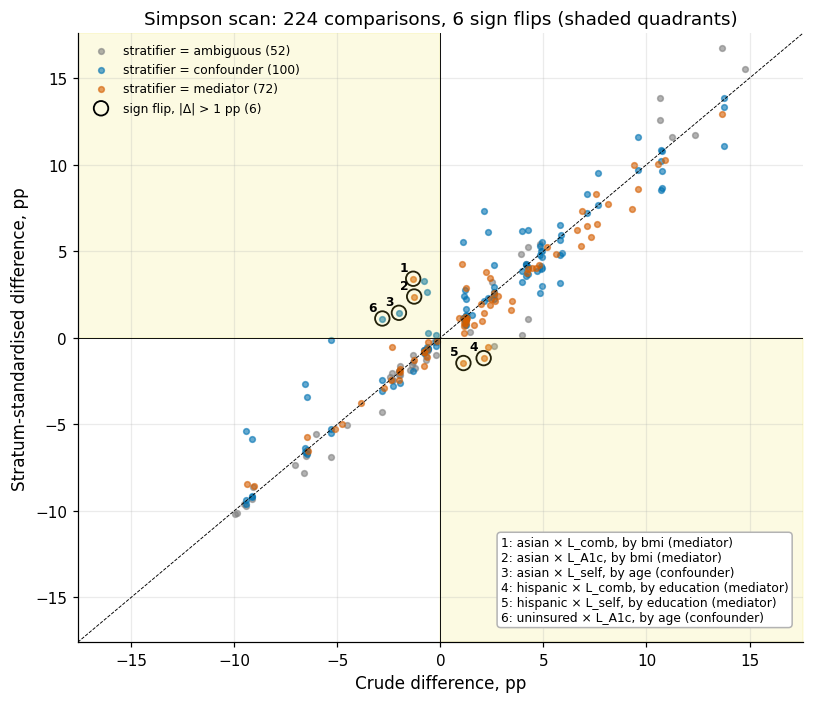

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
role_col = {"confounder": C.OKABE_ITO["blue"], "mediator": C.OKABE_ITO["vermillion"], "ambiguous": C.OKABE_ITO["grey"]}
for role, g in SCAN.groupby("role"):
    ax.scatter(g.crude, g["std"], s=14, alpha=0.6, color=role_col[role], label=f"stratifier = {role} ({len(g)})")
fl = SCAN[SCAN.flip]
ax.scatter(fl.crude, fl["std"], s=90, facecolors="none", edgecolors="k", lw=1.2, label=f"sign flip, |Δ| > 1 pp ({len(fl)})")
key = []
for i, r in enumerate(fl.itertuples(), 1):
    ax.annotate(str(i), (r.crude, r.std), fontsize=8, fontweight="bold", xytext=(-9, 5), textcoords="offset points")
    key.append(f"{i}: {r.exposure} × {r.outcome.split(' ')[0]}, by {r.stratifier} ({r.role})")
ax.text(0.98, 0.03, chr(10).join(key), transform=ax.transAxes, ha="right", va="bottom", fontsize=8, multialignment="left",
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
lim = np.nanmax(np.abs(SCAN[["crude", "std"]].to_numpy())) * 1.05
ax.plot([-lim, lim], [-lim, lim], color="k", lw=0.6, ls="--")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.fill_between([0, lim], -lim, 0, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.fill_between([-lim, 0], 0, lim, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Crude difference, pp"); ax.set_ylabel("Stratum-standardised difference, pp")
ax.set_title(f"Simpson scan: {len(SCAN)} comparisons, {len(fl)} sign flips (shaded quadrants)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plots.savefig(fig, "S4_simpson_scan",
              caption="Crude vs stratum-standardised weighted differences for every exposure x outcome x stratifier "
                      "combination; shaded quadrants = sign change; circled = flips with both |difference| > 1 pp. "
                      "Colour = DAG role of the stratifier.")
plt.show()

reg("DR-S4-06", "interpretation",
    f"Simpson scan: {len(SCAN)} comparisons, {int(SCAN.flip.sum())} sign flips, {int(SCAN.attenuation_50.sum())} attenuations > 50%; "
    f"{int((SCAN.flip & (SCAN.role == 'mediator')).sum())} flips come from mediator stratifiers (BMI, education).",
    "results/S4/simpson_scan.csv; figures/S4_simpson_scan.png",
    f"uninsured x L_A1c | age {ex_ins.crude:+.1f} -> {ex_ins['std']:+.1f} pp, P(sign differs) = {ex_ins.p_sign_differs:.2f}; "
    f"Asian x L_comb | age P(sign differs) = {ex_as.p_sign_differs:.2f} (B = {B})",
    "Treat the scan as exploratory; promote only DAG-supported (confounder-stratified) flips with CIs; never read BMI-stratified "
    "'flips' as de-confounding (BMI is a mediator / mismeasured proxy of adiposity).",
    "Reporting all flips as findings (multiple comparisons, mediator conditioning); hiding the scan.",
    check_note=f"process doc quotes 219 comparisons / 5 flips; the pre-declared grid here gives {len(SCAN)} (= 252 - 28 self-stratifications)")

**So what.** Sign flips are rare (a handful out of more than two hundred comparisons) and small:
every flipped standardised difference has a jackknife CI that includes zero, and the bootstrap
puts the probability that crude and standardised signs really differ well short of certainty. Two
kinds of flips must be read differently:

* **Age-stratified flips** (uninsured × `L_A1c`, Asian × `L_self`) are DAG-supported – age is a
  confounder – and repeat the §4.5–4.6 message: younger groups look healthier until age is
  removed. They remain exploratory because their intervals cover zero.
* **BMI- and education-stratified flips** (Asian × `L_comb`/`L_A1c` | BMI, Hispanic | education)
  are *mediator artefacts*. BMI sits on the path race → adiposity → BMI → diabetes, so comparing
  Asian and White adults "at the same BMI" answers a different question – and because BMI
  under-states adiposity in Asian adults (S5), equal-BMI strata are not equal-risk strata. This is
  the measurement-bias finding of S5 seen from another angle, not de-confounding.

Attenuations of more than half outnumber the flips. The largest is uninsured × `L_comb` | age
(about −5.3 → −0.1 pp): the same age-confounding mechanism as §4.6, now visible because uninsured
adults are younger. Most other attenuations involve SES "siblings" (income, education), which
partly measure the same construct and therefore also absorb each other. The process document's
"219 comparisons / 5 flips" came from an earlier, undocumented prototype grid; the pre-declared
grid above gives 224 comparisons, and its counts are reported as they are. The two quoted bootstrap
examples agree with that prototype (uninsured × `L_A1c` | age about −2.8 → +1.1 pp with a sign-change
probability around 0.7–0.8; Asian × `L_comb` | age close to a coin flip).

## 4.8 Causal structure (DAG)
**Why.** Whether stratifying on a variable removes bias (confounder) or creates it (mediator,
collider) is not a statistical property of the data – it follows from assumptions about how the
variables are generated. Writing those assumptions down as a DAG makes them checkable: the
adjustment sets used in §4.5–4.7 and in S5 are verified with the back-door criterion
(d-separation in networkx) instead of being asserted.

In [16]:
import networkx as nx

DAG_EDGES = [
    ("U: birth cohort / migration", "Race/ancestry"), ("U: birth cohort / migration", "Age"),
    ("Age", "Medicare"), ("Medicare", "Insurance"), ("SES", "Insurance"), ("Race/ancestry", "SES"),
    ("Insurance", "UsualCare"), ("SES", "UsualCare"), ("Age", "UsualCare"), ("UsualCare", "Diagnosis"),
    ("Race/ancestry", "Adiposity"), ("Age", "Adiposity"), ("Sex", "Adiposity"), ("SES", "Adiposity"),
    ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)"),     # body-composition: BMI-adiposity relation differs
    ("Adiposity", "Diabetes"), ("Age", "Diabetes"), ("Sex", "Diabetes"), ("Race/ancestry", "Diabetes"), ("SES", "Diabetes"),
    ("Diabetes", "Diagnosis"), ("Diagnosis", "Treatment"), ("Treatment", "HbA1c (measured)"), ("Diabetes", "HbA1c (measured)"),
    ("Diabetes", "ExamSelection"), ("SES", "ExamSelection"), ("Age", "ExamSelection"),
]
G = nx.DiGraph(DAG_EDGES)
assert nx.is_directed_acyclic_graph(G)
LATENT = {"U: birth cohort / migration", "Adiposity", "Diabetes"}      # not directly observed


def backdoor_ok(g, x, y, z):
    """Back-door criterion: Z has no descendant of X and d-separates X and Y once X's out-edges are cut."""
    z = set(z)
    if z & nx.descendants(g, x) or z & LATENT:
        return False
    g2 = g.copy()
    g2.remove_edges_from(list(g.out_edges(x)))
    return nx.is_d_separator(g2, {x}, {y}, z)


def minimal_sets(g, x, y, max_size=3):
    cand = sorted(set(g) - {x, y} - nx.descendants(g, x) - LATENT)
    found = []
    from itertools import combinations
    for k in range(0, max_size + 1):
        for z in combinations(cand, k):
            if backdoor_ok(g, x, y, z) and not any(set(f) <= set(z) for f in found):
                found.append(z)
    return found


queries = [
    ("Insurance", "Diagnosis", ["Age", "SES"], "Insurance → undiagnosed (S5)"),
    ("Insurance", "Diagnosis", ["Age"], "… age only"),
    ("Insurance", "Diagnosis", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex"], "Race → diabetes (§4.5)"),
    ("Race/ancestry", "Diabetes", ["Age"], "… age only"),
    ("Race/ancestry", "Diabetes", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "BMI (measured)"], "… + BMI"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "SES"], "… + SES (mediator)"),
    ("Insurance", "Diabetes", ["Age", "SES"], "Insurance → diabetes (§4.6)"),
]
DAG_TAB = pd.DataFrame([{"question": lab, "exposure": x, "outcome": y, "adjustment set": "{" + ", ".join(z) + "}",
                         "valid (back-door)": backdoor_ok(G, x, y, z),
                         "contains descendant of exposure": bool(set(z) & nx.descendants(G, x))}
                        for x, y, z, lab in queries])
print(DAG_TAB.to_string(index=False))
ms_ins = minimal_sets(G, "Insurance", "Diagnosis")
ms_race = minimal_sets(G, "Race/ancestry", "Diabetes")
print("\nminimal sufficient sets  Insurance -> Diagnosis:", ms_ins)
print("minimal sufficient sets  Race -> Diabetes:", ms_race)
# Selection: the cohort exists only for examined adults (conditioning on a collider)
g_noses = G.copy(); g_noses.remove_edge("SES", "Diabetes"); g_noses.remove_edge("SES", "Adiposity")
indep_without = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age"})
indep_given_sel = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age", "ExamSelection"})
print(f"\ncollider check (SES->diabetes edges removed): SES ⟂ Diabetes | Race, Age: {indep_without}; "
      f"after also conditioning on ExamSelection: {indep_given_sel}  -> selection into the exam opens a path")
assert DAG_TAB.loc[0, "valid (back-door)"] and DAG_TAB.loc[3, "valid (back-door)"] and not DAG_TAB.loc[6, "valid (back-door)"]
DAG_TAB.to_csv(S4_DIR / "dag_adjustment_sets.csv", index=False)
OUT["dag"] = {"n_nodes": G.number_of_nodes(), "n_edges": G.number_of_edges(),
              "minimal_sets_insurance_diagnosis": [list(z) for z in ms_ins],
              "minimal_sets_race_diabetes": [list(z) for z in ms_race],
              "bmi_adjustment_valid": bool(DAG_TAB.loc[6, "valid (back-door)"]), "exam_selection_opens_path": bool(indep_without and not indep_given_sel)}

                    question      exposure   outcome             adjustment set  valid (back-door)  contains descendant of exposure
Insurance → undiagnosed (S5)     Insurance Diagnosis                 {Age, SES}               True                            False
                  … age only     Insurance Diagnosis                      {Age}              False                            False
                     … crude     Insurance Diagnosis                         {}              False                            False
      Race → diabetes (§4.5) Race/ancestry  Diabetes                 {Age, Sex}               True                            False
                  … age only Race/ancestry  Diabetes                      {Age}               True                            False
                     … crude Race/ancestry  Diabetes                         {}              False                            False
                     … + BMI Race/ancestry  Diabetes {Age, Sex, BMI (measure

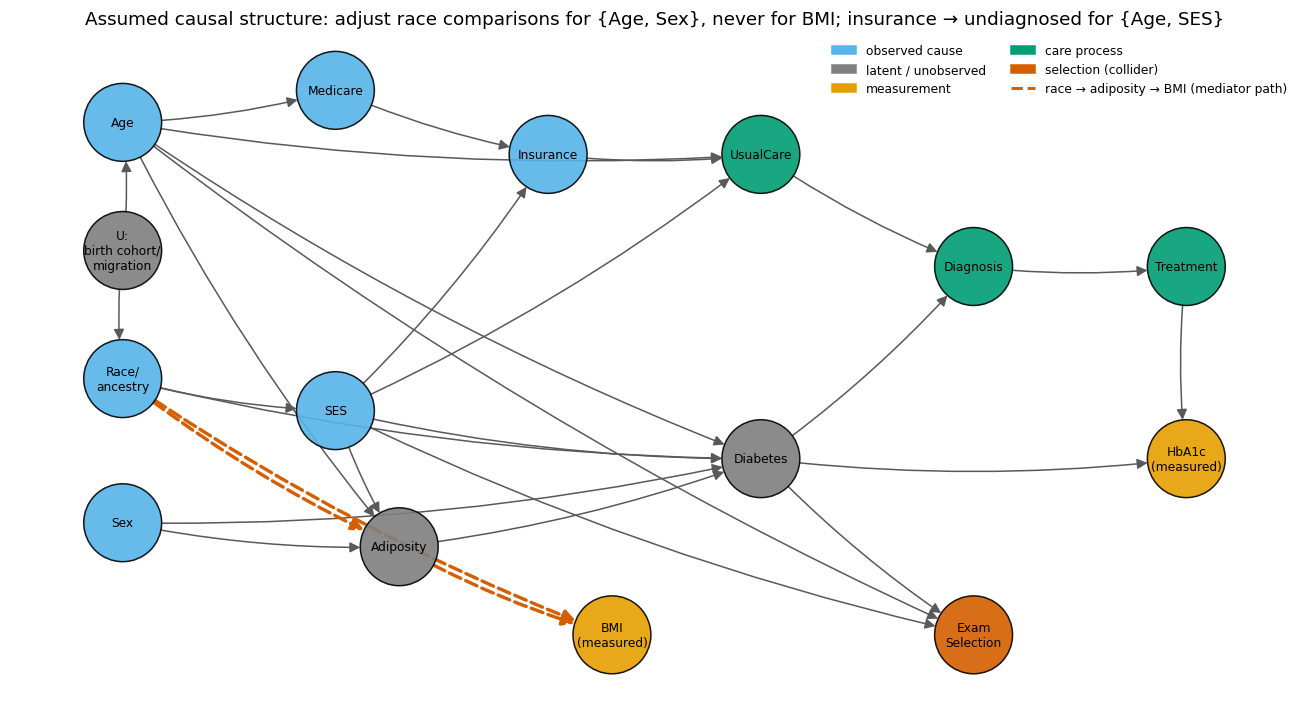

In [17]:
POS = {"U: birth cohort / migration": (0, 4.2), "Race/ancestry": (0, 2.6), "Age": (0, 5.8), "Sex": (0, 0.8),
       "SES": (2, 2.2), "Medicare": (2, 6.2), "Insurance": (4, 5.4), "UsualCare": (6, 5.4),
       "Adiposity": (2.6, 0.5), "BMI (measured)": (4.6, -0.6), "Diabetes": (6, 1.6), "Diagnosis": (8, 4.0),
       "Treatment": (10, 4.0), "HbA1c (measured)": (10, 1.6), "ExamSelection": (8, -0.6)}
KIND = {n: "latent" for n in LATENT} | {"BMI (measured)": "measure", "HbA1c (measured)": "measure",
                                        "ExamSelection": "selection", "Diagnosis": "process", "Treatment": "process",
                                        "UsualCare": "process"}
KCOL = {"latent": C.OKABE_ITO["grey"], "measure": C.OKABE_ITO["orange"], "selection": C.OKABE_ITO["vermillion"],
        "process": C.OKABE_ITO["green"], "observed": C.OKABE_ITO["sky"]}
fig, ax = plt.subplots(figsize=(12, 6.5))
cols_ = [KCOL[KIND.get(n, "observed")] for n in G.nodes]
nx.draw_networkx_nodes(G, POS, ax=ax, node_color=cols_, node_size=2600, alpha=0.9,
                       node_shape="o", linewidths=1, edgecolors="k")
mediator_edges = [("Race/ancestry", "Adiposity"), ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)")]
nx.draw_networkx_edges(G, POS, ax=ax, edgelist=[e for e in G.edges if e not in mediator_edges], arrows=True,
                       arrowsize=14, node_size=2600, edge_color="0.35", connectionstyle="arc3,rad=0.06")
nx.draw_networkx_edges(G, POS, ax=ax, edgelist=mediator_edges, arrows=True, arrowsize=16, width=2.2, node_size=2600,
                       edge_color=C.OKABE_ITO["vermillion"], style="dashed", connectionstyle="arc3,rad=0.06")
nx.draw_networkx_labels(G, POS, ax=ax, labels={n: n.replace(" (measured)", "\n(measured)").replace(": ", ":\n").replace(" / ", "/\n").replace("/ancestry", "/\nancestry").replace("ExamSelection", "Exam\nSelection") for n in G},
                        font_size=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=KCOL[k], label=lab) for k, lab in
                   [("observed", "observed cause"), ("latent", "latent / unobserved"), ("measure", "measurement"),
                    ("process", "care process"), ("selection", "selection (collider)")]] +
          [plt.Line2D([], [], color=C.OKABE_ITO["vermillion"], ls="--", lw=2, label="race → adiposity → BMI (mediator path)")],
          loc="upper right", fontsize=8, ncol=2)
ax.set_title("Assumed causal structure: adjust race comparisons for {Age, Sex}, never for BMI; insurance → undiagnosed for {Age, SES}")
ax.axis("off")
fig.tight_layout()
plots.savefig(fig, "S4_dag", caption="Directed acyclic graph of the assumed data-generating process (networkx); "
                                     "adjustment sets verified with the back-door criterion in §4.8.")
plt.show()

reg("DR-S4-07", "method", "In the DAG, BMI is a descendant of race (race -> adiposity -> BMI) and of SES; ExamSelection is a collider.",
    "figures/S4_dag.png; results/S4/dag_adjustment_sets.csv",
    f"back-door valid: race->diabetes | {{Age, Sex}} = True, + BMI = False; insurance->diagnosis | {{Age, SES}} = True; minimal sets {ms_ins}",
    "Adjust race comparisons for age (and sex) only; never present BMI-adjusted race contrasts as de-confounded; "
    "model coefficients are associations (no Table 2 fallacy).",
    "Adjusting for every available covariate (includes mediators and descendants); reading logistic coefficients causally.",
    check_note="adjustment sets verified with networkx d-separation")

**So what.** Under the stated assumptions, {Age, SES} is a sufficient adjustment set for the
insurance → undiagnosed question of S5 (age alone is not, because SES drives both insurance and
care), and {Age} or {Age, Sex} suffices for race → diabetes. Adding BMI breaks the back-door
criterion: BMI is a descendant of race through adiposity, so "BMI-adjusted" race contrasts – and the
BMI-stratified flips of §4.7 – estimate something other than the total association. The graph also
makes two structural biases explicit: the cohort exists only for people who attended the exam
(conditioning on the collider *ExamSelection* opens SES ↔ diabetes paths, only partly repaired by
the weights), and the HbA1c-based label is a descendant of *Treatment*, so conditioning on
HbA1c ≥ 6.5 (as the undiagnosed domain does) inherits the treatment-masking problem quantified in
S5. The prediction models of S7 are not causal: their coefficients are associations conditional on
everything else in the model (Westreich & Greenland's "Table 2 fallacy").

## 4.9 Redundancy and collinearity
**Why.** Several candidate features are arithmetic functions of each other (BMI = weight/height²,
WHtR = waist/height, LDL is computed from TC, HDL and triglycerides) or repeated measurements of
one quantity (three systolic and three diastolic readings). Such redundancy inflates coefficient
variance and makes coefficients uninterpretable. Variance inflation factors (VIF) quantify it; they
are read with O'Brien (2007) in mind – a high VIF is a reason to look at the structure, not an
automatic deletion rule.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

VIF_SETS = {
    "raw_anthropometry": ["BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC"],
    "ht_bmi": ["BMXHT", "BMXBMI"],
    "bmi_waist": ["BMXBMI", "BMXWAIST"],
    "bp_readings": ["BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"],
    "bp_means": ["bp_sys_mean", "bp_dia_mean"],
    "tier1_candidates": ["RIDAGEYR", "BMXBMI", "BMXWAIST", "bp_sys_mean", "INDFMPIR"],
    "tier2_candidates": ["RIDAGEYR", "BMXBMI", "bp_sys_mean", "LBXTC", "LBDHDD"],
}
vif_rows = []
for set_name, cols in VIF_SETS.items():
    x = coh[cols].dropna()
    X = sm.add_constant(x.to_numpy(float))
    for i, c in enumerate(cols):
        vif_rows.append({"set": set_name, "variable": c, "vif": variance_inflation_factor(X, i + 1), "n": len(x)})
VIF = pd.DataFrame(vif_rows)
VIF.to_csv(S4_DIR / "vif_table.csv", index=False)
print(VIF.pivot_table(index="variable", columns="set", values="vif", sort=False).round(1).fillna("").to_string())
print("n per set:", VIF.groupby("set", sort=False).n.first().to_dict())

v = VIF.set_index(["set", "variable"]).vif
assert abs(v[("raw_anthropometry", "BMXWT")] - 95.7) < 0.1 and abs(v[("raw_anthropometry", "BMXBMI")] - 97.6) < 0.1
bp = VIF.query("set == 'bp_readings'").vif
assert abs(bp.min() - 8.8) < 0.1 and abs(bp.max() - 11.7) < 0.1

a = coh[["BMXBMI", "BMXWT", "BMXHT"]].dropna()
r_struct = np.corrcoef(np.log(a.BMXBMI), np.log(a.BMXWT) - 2 * np.log(a.BMXHT / 100))[0, 1]
fast_ok = coh[C.WEIGHT_FASTING].fillna(0) > 0
lip = coh.loc[fast_ok, ["LBXTC", "LBDLDL"]].dropna()
r_tc_ldl = lip.corr().iloc[0, 1]
print(f"\nstructural redundancy: corr(log BMI, log W - 2 log H) = {r_struct:.5f} (n = {len(a):,})")
print(f"TC vs LDL (fasting subsample, n = {len(lip):,}): Pearson r = {r_tc_ldl:.3f}")
OUT["vif"] = {s: {r.variable: r.vif for r in g.itertuples()} for s, g in VIF.groupby("set", sort=False)}
OUT["redundancy"] = {"r_logbmi_logw_2logh": r_struct, "r_tc_ldl": r_tc_ldl, "n_tc_ldl": len(lip)}

set         raw_anthropometry ht_bmi bmi_waist bp_readings bp_means tier1_candidates tier2_candidates
variable                                                                                             
BMXWT                    95.7                                                                        
BMXHT                    21.6    1.0                                                                 
BMXBMI                   97.6    1.0       5.1                                   5.8              1.1
BMXWAIST                  7.1              5.1                                   5.9                 
BMXHIP                    7.7                                                                        
BMXARMC                   6.6                                                                        
BPXOSY1                                               10.5                                           
BPXOSY2                                               11.7                        

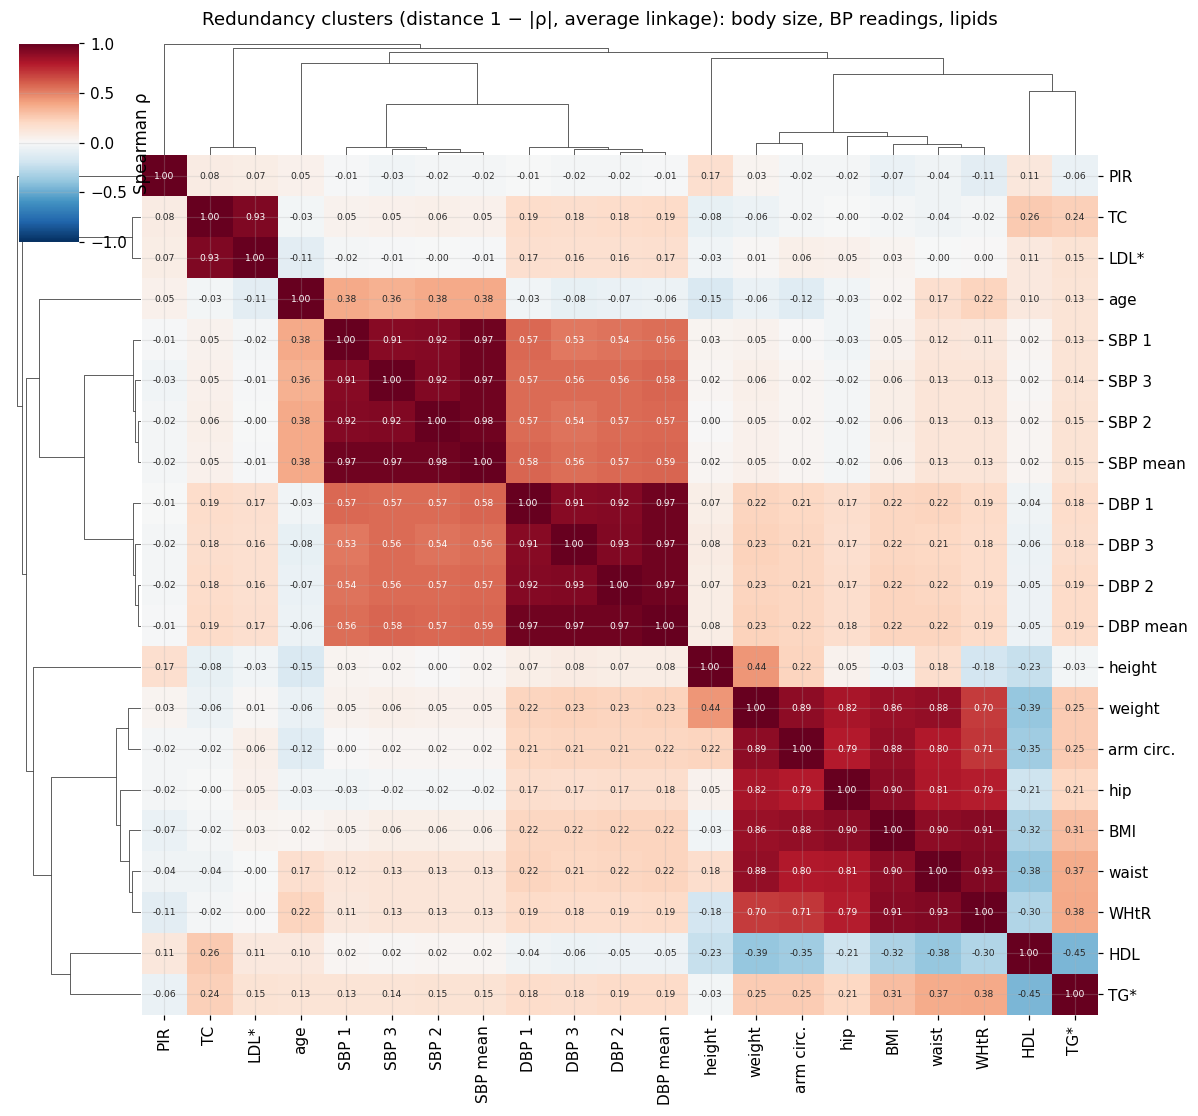

clusters with |rho| >= 0.7 (average linkage): [['TC', 'LDL*'], ['SBP 1', 'SBP 2', 'SBP 3', 'SBP mean'], ['DBP 1', 'DBP 2', 'DBP 3', 'DBP mean'], ['BMI', 'weight', 'waist', 'hip', 'arm circ.', 'WHtR']]


In [19]:
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

SPEAR_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWT": "weight", "BMXHT": "height", "BMXWAIST": "waist",
              "BMXHIP": "hip", "BMXARMC": "arm circ.", "whtr": "WHtR", "BPXOSY1": "SBP 1", "BPXOSY2": "SBP 2",
              "BPXOSY3": "SBP 3", "BPXODI1": "DBP 1", "BPXODI2": "DBP 2", "BPXODI3": "DBP 3",
              "bp_sys_mean": "SBP mean", "bp_dia_mean": "DBP mean", "LBXTC": "TC", "LBDHDD": "HDL",
              "LBDLDL": "LDL*", "LBXTLG": "TG*", "INDFMPIR": "PIR"}
sp = coh[list(SPEAR_VARS)].copy()
sp.loc[~fast_ok, ["LBDLDL", "LBXTLG"]] = np.nan                     # fasting analytes only where valid
rho = sp.rename(columns=SPEAR_VARS).corr(method="spearman")          # pairwise complete
dist = 1 - rho.abs()
link = hierarchy.linkage(squareform(dist.to_numpy(), checks=False), method="average")
cg = sns.clustermap(rho, row_linkage=link, col_linkage=link, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                    annot=True, fmt=".2f", annot_kws={"fontsize": 6}, figsize=(11, 10),
                    cbar_kws={"label": "Spearman ρ"}, dendrogram_ratio=0.12)
cg.fig.suptitle("Redundancy clusters (distance 1 − |ρ|, average linkage): body size, BP readings, lipids", y=1.01)
plots.savefig(cg.fig, "S4_spearman_clustermap",
              caption="Clustered Spearman correlation heatmap of candidate predictors (pairwise complete; *LDL and "
                      "triglycerides on the valid fasting subsample only).")
plt.show()
clusters = pd.Series(hierarchy.fcluster(link, t=1 - 0.7, criterion="distance"), index=rho.index)
groups = [list(g.index) for _, g in clusters.groupby(clusters) if len(g) > 1]
print("clusters with |rho| >= 0.7 (average linkage):", groups)
OUT["redundancy"]["clusters_rho07"] = groups

**So what.** Weight (VIF 95.7) and BMI (97.6) are almost perfectly predictable from the other body
measurements, and the reason is structural, not statistical: log BMI is an exact linear function of
log weight and log height (correlation 0.99999). Height and BMI on their own are unrelated (VIF 1.0),
BMI and waist share variance (5.1) but measure different things (total vs central adiposity), and
the six blood-pressure readings (8.8–11.7) collapse to VIF 1.6 once replaced by their means. The
candidate Tier-1 set [age, BMI, waist, SBP, PIR] stays below 6 and the Tier-2 set [age, BMI, SBP,
TC, HDL] below 1.2. TC and LDL correlate at 0.94 because LDL is calculated from TC. Decision:
drop weight, height, hip and arm circumference (structural duplicates of BMI/waist), use mean SBP/DBP,
exclude LDL (fasting-only and derived from TC), and keep BMI + waist with L2 penalisation as the
second line of defence. The clustered heatmap shows the same three redundancy blocks (body size,
blood pressure, lipids) visually.

## 4.10 Skewness
**Why.** Strong right skew lets a few extreme values dominate a linear predictor and the
penalisation. We measure skewness before and after log and Yeo–Johnson transforms. Triglycerides
are a fasting analyte: they are only valid where the fasting weight is positive (8–24 h fast).

In [20]:
SKEW_VARS = [("BMXBMI", "BMI"), ("bp_sys_mean", "SBP mean"), ("LBDHDD", "HDL"), ("BMXWAIST", "waist"),
             ("LBXTC", "total cholesterol"), ("INDFMPIR", "PIR")]
skew_rows = []
def _skew_row(x, var, label, subsample):
    x = x.dropna().astype(float)
    yj, lam = stats.yeojohnson(x)
    return {"variable": var, "label": label, "subsample": subsample, "n": len(x), "skew_raw": stats.skew(x),
            "skew_log": stats.skew(np.log(x)) if (x > 0).all() else np.nan, "skew_yj": stats.skew(yj), "yj_lambda": lam}
for var, label in SKEW_VARS:
    skew_rows.append(_skew_row(coh[var], var, label, "cohort"))
skew_rows.append(_skew_row(coh.loc[fast_ok, "LBXTLG"], "LBXTLG", "triglycerides", "fasting (WTSAF2YR > 0)"))
skew_rows.append(_skew_row(coh["LBXTLG"], "LBXTLG", "triglycerides", "all with a value (incl. WTSAF2YR = 0)"))
SKEW = pd.DataFrame(skew_rows)
SKEW.to_csv(S4_DIR / "skew_table.csv", index=False)
print(SKEW.round(2).to_string(index=False))
sk = SKEW.set_index(["variable", "subsample"])
assert abs(sk.loc[("BMXBMI", "cohort"), "skew_raw"] - 1.22) < 0.01 and abs(sk.loc[("BMXBMI", "cohort"), "skew_yj"]) < 0.01
tg_f, tg_all = sk.loc[("LBXTLG", "fasting (WTSAF2YR > 0)")], sk.loc[("LBXTLG", "all with a value (incl. WTSAF2YR = 0)")]
print(f"\ntriglycerides: valid fasting n = {tg_f.n:,}, skew {tg_f.skew_raw:.2f} -> log {tg_f.skew_log:.2f}; "
      f"including {tg_all.n - tg_f.n} non-fasting rows: skew {tg_all.skew_raw:.2f} -> log {tg_all.skew_log:.2f}")
OUT["skew"] = {f"{r.variable}|{r.subsample}": {"n": r.n, "raw": r.skew_raw, "log": r.skew_log, "yj": r.skew_yj,
                                               "lambda": r.yj_lambda} for r in SKEW.itertuples()}

reg("DR-S4-08", "preparation", "Structural redundancy: weight VIF 95.7, BMI 97.6 (BMI = W/H^2, r = 0.99999); six BP readings VIF 8.8-11.7; TC-LDL r = 0.94.",
    "results/S4/vif_table.csv; figures/S4_spearman_clustermap.png",
    f"BP means VIF {v[('bp_means', 'bp_sys_mean')]:.1f}; Tier-1 max VIF {VIF[VIF.set == 'tier1_candidates'].vif.max():.1f}; "
    f"Tier-2 max {VIF[VIF.set == 'tier2_candidates'].vif.max():.1f}",
    "Drop weight, height, hip, arm circumference; average BP readings; exclude LDL; keep BMI + waist (or WHtR, S8) under L2.",
    "Automatic VIF > 10 deletion (O'Brien 2007); PCA of body measures (destroys interpretability).",
    check_note="VIFs re-computed; n = 5,388 for the raw anthropometry set")
reg("DR-S4-09", "preparation", "Right skew: BMI 1.22, SBP 0.93, HDL 1.08; triglycerides 6.62 on the valid fasting subsample.",
    "results/S4/skew_table.csv",
    f"BMI 1.22 -> log {sk.loc[('BMXBMI','cohort'),'skew_log']:.2f} -> YJ {sk.loc[('BMXBMI','cohort'),'skew_yj']:.2f}; TG {tg_f.skew_raw:.2f} (n {tg_f.n}) vs {tg_all.skew_raw:.2f} incl. non-fasting",
    "Offer Yeo-Johnson as a toggleable step fitted inside training folds only; the S7 ablation decides; triglycerides are not a T1/T2 feature.",
    "Transform on the full data before splitting (leakage of lambda); log for variables that can be 0 (PIR).",
    check_verdict="PASS-FIX", check_note="process doc 6.23 for triglycerides includes 235 non-fasting rows (WTSAF2YR = 0); valid fasting value 6.62")

   variable             label                             subsample    n  skew_raw  skew_log  skew_yj  yj_lambda
     BMXBMI               BMI                                cohort 5649      1.22      0.42    -0.00      -0.65
bp_sys_mean          SBP mean                                cohort 5550      0.93      0.38    -0.01      -0.79
     LBDHDD               HDL                                cohort 5459      1.08      0.21     0.00      -0.29
   BMXWAIST             waist                                cohort 5470      0.58      0.12     0.00      -0.27
      LBXTC total cholesterol                                cohort 5459      0.54     -0.25     0.01       0.32
   INDFMPIR               PIR                                cohort 4996     -0.07       NaN    -0.17       0.77
     LBXTLG     triglycerides                fasting (WTSAF2YR > 0) 2820      6.62      0.60    -0.01      -0.35
     LBXTLG     triglycerides all with a value (incl. WTSAF2YR = 0) 3055      6.23      0.57    

**So what.** BMI, SBP and HDL are moderately right-skewed (≈ 0.9–1.2); a log transform removes most
of it and Yeo–Johnson removes all of it (BMI λ ≈ −0.65). Total cholesterol and waist are nearly
symmetric. Triglycerides are extremely skewed (≈ 6.6 on the 2,820 valid fasting adults). The
process document's 6.23 was computed without the fasting-weight restriction; in the cohort that
adds 235 people whose fast fell outside 8–24 h (`WTSAF2YR = 0`), whose values are not valid fasting
measurements (and the 6.23 → 0.54 pair matches all 3,517 participants with a value, teenagers
included). This is the same trap that the XPT zero artefact sets (a zero weight read as
5.4 × 10⁻⁷⁹ passes a `> 0` filter). Because logistic regression is not distributional, skewness
matters only through leverage; the transform is therefore a toggleable preparation step whose λ is
fitted inside the training folds, and whether it helps is decided by the S7 ablation, not here.

## 4.11 Linearity
**Why.** A plain logistic regression assumes each continuous predictor acts linearly on the
log-odds. If that is wrong, the model under-fits exactly where risk changes fastest. We test it with
restricted cubic splines (Harrell): each variable gets a 4-knot RCS (knots at the 5/35/65/95th
percentiles, 2 extra df) and a likelihood-ratio test against the linear term, with the other six
continuous predictors linear and sex adjusted; complete cases for all seven variables, outcome
`L_comb`, unweighted (a model-structure question, not a population estimate).

In [21]:
import statsmodels.formula.api as smf

LIN_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWAIST": "waist", "bp_sys_mean": "SBP (mean)",
            "LBDHDD": "HDL", "LBXTC": "total cholesterol", "INDFMPIR": "PIR"}


def rcs_basis(x, q=(0.05, 0.35, 0.65, 0.95)):
    """Harrell restricted cubic spline basis (linear term + k-2 non-linear terms), knots at quantiles."""
    x = np.asarray(x, float)
    t = np.quantile(x, q)
    k = len(t)
    p3 = lambda u: np.maximum(u, 0) ** 3
    nl = [(p3(x - t[j]) - p3(x - t[k - 2]) * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
           + p3(x - t[k - 1]) * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2])) / (t[k - 1] - t[0]) ** 2 for j in range(k - 2)]
    return np.column_stack([x] + nl), t


lin = coh.dropna(subset=list(LIN_VARS)).reset_index(drop=True)
lin["female"] = (lin.sex == "Female").astype(float)
y_lin = lin.L_comb.to_numpy(float)
fit_logit = lambda X: sm.Logit(y_lin, sm.add_constant(X)).fit(disp=0)
lin_rows = []
for v, lab in LIN_VARS.items():
    others = lin[[o for o in LIN_VARS if o != v] + ["female"]].to_numpy(float)
    basis, knots = rcs_basis(lin[v])
    m_lin = fit_logit(np.column_stack([basis[:, :1], others]))
    m_rcs = fit_logit(np.column_stack([basis, others]))
    chi2 = 2 * (m_rcs.llf - m_lin.llf)
    dfree = basis.shape[1] - 1
    lin_rows.append({"variable": v, "label": lab, "n": len(lin), "n_events": int(y_lin.sum()), "chi2": chi2, "df": dfree,
                     "p": stats.chi2.sf(chi2, dfree), "knots": np.round(knots, 1).tolist()})
LIN = pd.DataFrame(lin_rows)
LIN["nonlinear"] = LIN.p < 0.05
LIN.to_csv(S4_DIR / "linearity_tests.csv", index=False)
print(LIN.assign(p=LIN.p.map(lambda p: f"{p:.2g}")).round(2).to_string(index=False))
expected = {"RIDAGEYR": 57.6, "BMXBMI": 11.6, "BMXWAIST": 7.1, "bp_sys_mean": 5.9, "LBDHDD": 18.5, "LBXTC": 41.8, "INDFMPIR": 0.8}
assert len(lin) == 4478 and all(abs(LIN.set_index("variable").chi2[k] - e) < 0.1 for k, e in expected.items())
OUT["linearity"] = {r.variable: {"label": r.label, "chi2": r.chi2, "df": r.df, "p": r.p} for r in LIN.itertuples()}
OUT["linearity_n"] = {"n": len(lin), "events": int(y_lin.sum())}

   variable             label    n  n_events  chi2  df       p                        knots  nonlinear
   RIDAGEYR               age 4478       722 57.61   2 3.1e-13     [25.0, 47.0, 63.0, 79.0]       True
     BMXBMI               BMI 4478       722 11.56   2  0.0031     [20.5, 26.2, 31.1, 42.6]       True
   BMXWAIST             waist 4478       722  7.05   2   0.029   [76.4, 93.3, 106.5, 130.9]       True
bp_sys_mean        SBP (mean) 4478       722  5.87   2   0.053  [98.3, 114.3, 127.0, 154.4]      False
     LBDHDD               HDL 4478       722 18.47   2 9.8e-05     [35.0, 48.0, 58.0, 82.0]       True
      LBXTC total cholesterol 4478       722 41.77   2 8.5e-10 [125.0, 171.0, 202.0, 260.1]       True
   INDFMPIR               PIR 4478       722  0.83   2    0.66         [0.5, 2.1, 4.1, 5.0]      False


**Binned empirical log-odds.** The test says *whether* a curve is needed; the binned plot shows
*what shape* it has. Points are the observed log-odds in deciles (95 % CI); lines are univariable
linear and RCS logistic fits.

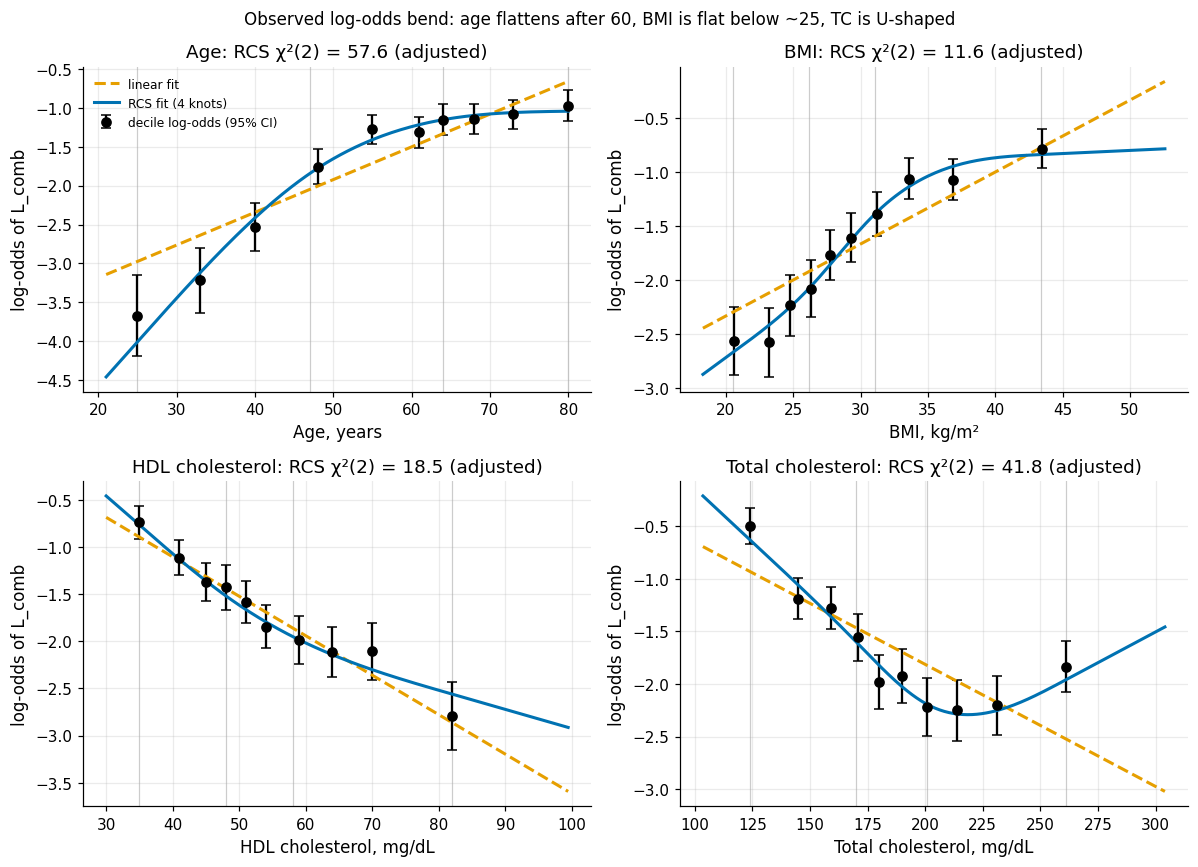

BMI deciles (median, log-odds): [(20.6, -2.56), (23.2, -2.57), (24.8, -2.23), (26.3, -2.08), (27.7, -1.76), (29.3, -1.61), (31.2, -1.39), (33.6, -1.06), (36.9, -1.07), (43.5, -0.78)]
age deciles (median, log-odds): [(25.0, -3.67), (33.0, -3.22), (40.0, -2.53), (48.0, -1.76), (55.0, -1.28), (61.0, -1.32), (64.0, -1.15), (68.0, -1.14), (73.0, -1.09), (80.0, -0.97)]


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
binned = {}
for ax, (v, lab) in zip(axes.ravel(), [("RIDAGEYR", "Age, years"), ("BMXBMI", "BMI, kg/m²"),
                                       ("LBDHDD", "HDL cholesterol, mg/dL"), ("LBXTC", "Total cholesterol, mg/dL")]):
    d = coh[[v, "L_comb"]].dropna()
    d["bin"] = pd.qcut(d[v], 10, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(x=(v, "median"), n=("L_comb", "size"), k=("L_comb", "sum"))
    pr = (g.k + 0.5) / (g.n + 1)
    lo_ = np.log(pr / (1 - pr)); se = np.sqrt(1 / (g.k + 0.5) + 1 / (g.n - g.k + 0.5))
    ax.errorbar(g.x, lo_, yerr=1.96 * se, fmt="o", color="k", capsize=3, label="decile log-odds (95% CI)")
    grid = np.linspace(d[v].quantile(0.01), d[v].quantile(0.99), 200)
    B, kn = rcs_basis(d[v])
    m_r = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(B)).fit(disp=0)
    p3 = lambda u: np.maximum(u, 0) ** 3
    k_ = len(kn)
    Bg = np.column_stack([grid] + [(p3(grid - kn[j]) - p3(grid - kn[k_ - 2]) * (kn[k_ - 1] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])
                                    + p3(grid - kn[k_ - 1]) * (kn[k_ - 2] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])) / (kn[k_ - 1] - kn[0]) ** 2
                                   for j in range(k_ - 2)])
    m_l = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(d[[v]].to_numpy(float))).fit(disp=0)
    ax.plot(grid, m_l.params[0] + m_l.params[1] * grid, color=C.OKABE_ITO["orange"], lw=2, ls="--", label="linear fit")
    ax.plot(grid, sm.add_constant(Bg) @ m_r.params, color=C.OKABE_ITO["blue"], lw=2, label="RCS fit (4 knots)")
    for kv in kn:
        ax.axvline(kv, color="0.8", lw=0.8, zorder=0)
    ax.set_xlabel(lab); ax.set_ylabel("log-odds of L_comb")
    ax.set_title(f"{lab.split(',')[0]}: RCS χ²(2) = {LIN.set_index('variable').chi2[v]:.1f} (adjusted)")
    binned[v] = pd.DataFrame({"median": g.x.to_numpy(), "logodds": lo_.to_numpy(), "n": g.n.to_numpy()})
axes[0, 0].legend(fontsize=8)
fig.suptitle("Observed log-odds bend: age flattens after 60, BMI is flat below ~25, TC is U-shaped", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S4_binned_logodds", caption="Decile-binned empirical log-odds of L_comb (unweighted, 95% CI) with "
                                                "univariable linear and 4-knot restricted cubic spline fits; grey lines = knots.")
plt.show()
bmi_b = binned["BMXBMI"]; age_b = binned["RIDAGEYR"]
print("BMI deciles (median, log-odds):", [(round(a, 1), round(b, 2)) for a, b in zip(bmi_b["median"], bmi_b.logodds)])
print("age deciles (median, log-odds):", [(round(a, 0), round(b, 2)) for a, b in zip(age_b["median"], age_b.logodds)])
OUT["binned_logodds"] = {lab: df_.to_dict("list") for lab, df_ in binned.items()}

**So what.** Five of the seven continuous predictors depart from linearity on the log-odds scale:
age (χ² ≈ 57.6), total cholesterol (≈ 41.8), HDL (≈ 18.5), BMI (≈ 11.6) and waist (≈ 7.1); SBP is
borderline (p ≈ 0.05) and PIR is linear (p ≈ 0.7). The shapes are monotone-but-curved for age (risk
rises steeply to about 60, then flattens) and BMI (log-odds about −2.6 in the two lowest deciles,
i.e. flat below about 24, then rising and levelling off above about 35), while
total cholesterol is U-shaped – the low end most plausibly reflects statin treatment *after*
diagnosis (reverse causation), a warning for interpreting any Tier-2 coefficient. Consequence: the
main model is an L2 logistic regression with cubic B-splines (`SplineTransformer`, 4 quantile knots,
linear extrapolation – the `C.SPLINE_KW` configuration) on continuous predictors, with a linear arm
kept as an ablation.

## 4.12 Interactions and power
**Why.** If the BMI–diabetes slope differed by race (as the S5 measurement-bias finding suggests it
might for Asian adults), the model would need an interaction term. A non-significant test is only
informative together with its power, so we also report the minimum detectable effect (MDE, 80 %
power, two-sided α = 0.05) and repeat the tests under three model specifications (`C(...)` is avoided
in the formulas because `C` is the project config module here; race is an ordered categorical with
NH White as reference).

In [23]:
inter = lin.rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi", "BMXWAIST": "waist", "bp_sys_mean": "sbp",
                            "LBDHDD": "hdl", "LBXTC": "tc", "INDFMPIR": "pir"}).copy()
inter["race6"] = pd.Categorical(inter.race.astype(str), categories=list(io.RACE_ORDER))   # NH White = reference
inter["asian"] = (inter.race == "NH Asian").astype(float)
for v in ["age", "bmi"]:
    Bv, _ = rcs_basis(inter[v]); inter[f"{v}_s1"], inter[f"{v}_s2"] = Bv[:, 1], Bv[:, 2]
bmi_cc = coh.dropna(subset=["BMXBMI"]).rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi"}).copy()
bmi_cc["female"] = (bmi_cc.sex == "Female").astype(float)
bmi_cc["race6"] = pd.Categorical(bmi_cc.race.astype(str), categories=list(io.RACE_ORDER))
bmi_cc["asian"] = (bmi_cc.race == "NH Asian").astype(float)
SPECS = {
    "A_primary": (inter, "age + female + race6 + bmi + waist + sbp + hdl + tc + pir"),
    "B_minimal": (bmi_cc, "age + female + race6 + bmi"),
    "C_splines": (inter, "age + age_s1 + age_s2 + bmi + bmi_s1 + bmi_s2 + female + race6"),
}
TERMS = {"race_x_bmi": "race6:bmi", "asian_x_bmi": "asian:bmi", "age_x_bmi": "age:bmi",
         "sex_x_bmi": "female:bmi"}
z80 = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
int_rows = []
for spec, (d, base) in SPECS.items():
    m0 = smf.logit(f"L_comb ~ {base}", d).fit(disp=0)
    for term, expr in TERMS.items():
        m1 = smf.logit(f"L_comb ~ {base} + {expr}", d).fit(disp=0)
        chi2 = 2 * (m1.llf - m0.llf); k = int(m1.df_model - m0.df_model)
        mde = np.nan
        if k == 1:
            name = [p for p in m1.params.index if p not in m0.params.index][0]
            mde = z80 * m1.bse[name] * 5                     # log-OR difference per 5 kg/m² BMI (per year x 5 for age)
        int_rows.append({"term": term, "spec": spec, "n": int(m1.nobs), "chi2": chi2, "df": k,
                         "p": stats.chi2.sf(chi2, k), "mde": mde})
INT = pd.DataFrame(int_rows)
INT["verdict"] = np.where(INT.p < 0.05, "detected", "not detected")
INT.to_csv(S4_DIR / "interaction_tests.csv", index=False)
print(INT.pivot(index="term", columns="spec", values="p").round(3).to_string())
prim = INT[INT.spec == "A_primary"].set_index("term")
mde_asian = prim.loc["asian_x_bmi", "mde"]
print(f"\nprimary spec (n = {int(prim.n.iloc[0]):,}): race x BMI chi2({int(prim.loc['race_x_bmi','df'])}) = "
      f"{prim.loc['race_x_bmi','chi2']:.2f}, p = {prim.loc['race_x_bmi','p']:.2f}; Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; "
      f"age x BMI p = {prim.loc['age_x_bmi','p']:.2f}; sex x BMI p = {prim.loc['sex_x_bmi','p']:.3f}")
print(f"MDE (80% power) for the Asian x BMI slope difference: {mde_asian:.2f} log-OR per 5 kg/m² "
      f"(odds-ratio multiplier {np.exp(mde_asian):.2f} per 5 kg/m²)")
race_p_range = (INT[INT.term == "race_x_bmi"].p.min(), INT[INT.term == "race_x_bmi"].p.max())
sex_p_range = (INT[INT.term == "sex_x_bmi"].p.min(), INT[INT.term == "sex_x_bmi"].p.max())
assert race_p_range[0] > 0.05 and INT[INT.term == "asian_x_bmi"].p.min() > 0.05
OUT["interactions"] = {r.term: {"chi2": r.chi2, "df": r.df, "p": r.p, "mde": r.mde} for r in prim.reset_index().itertuples()}
OUT["interactions_by_spec"] = INT.to_dict("records")

reg("DR-S4-10", "model", "Non-linearity: RCS LR chi2(2) age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (p < 0.05); SBP 5.9 (p 0.053); PIR 0.8.",
    "results/S4/linearity_tests.csv; figures/S4_binned_logodds.png",
    f"n = {len(lin):,}, events {int(y_lin.sum())}",
    "Main model: L2 logistic regression with SplineTransformer(n_knots=4, degree=3, knots='quantile', extrapolation='linear') on continuous features; linear arm as ablation.",
    "Plain linear logit (misses curvature); fixed-cut categorisation (loses information, arbitrary cut-points); GAM/boosting (outside HR3).")
reg("DR-S4-11", "model", "Interactions with BMI not detectable: race x BMI and Asian x BMI non-significant under all three specifications.",
    "results/S4/interaction_tests.csv",
    f"primary: race x BMI p = {prim.loc['race_x_bmi','p']:.2f}, Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; MDE Asian x BMI {mde_asian:.2f} log-OR per 5 kg/m²; "
    f"sex x BMI p range {sex_p_range[0]:.3f}-{sex_p_range[1]:.2f} (specification-dependent)",
    "No interaction terms in the main model ('not detectable, underpowered', not 'absent'); the Asian BMI problem is addressed as measurement (WHtR, S5/S8), not by an interaction.",
    "Adding race x BMI terms (cost variance, power too low to estimate them); claiming no interaction exists.",
    check_verdict="PASS-FIX", check_note="process doc p-values 0.42/0.83/0.20/0.48 not reproducible exactly (spec undocumented); conclusions for race terms hold in every spec, sex x BMI is spec-dependent")

spec         A_primary  B_minimal  C_splines
term                                        
age_x_bmi        0.445      0.435      0.050
asian_x_bmi      0.933      0.945      0.789
race_x_bmi       0.393      0.393      0.172
sex_x_bmi        0.008      0.833      0.072

primary spec (n = 4,478): race x BMI chi2(5) = 5.19, p = 0.39; Asian x BMI p = 0.93; age x BMI p = 0.45; sex x BMI p = 0.008
MDE (80% power) for the Asian x BMI slope difference: 0.70 log-OR per 5 kg/m² (odds-ratio multiplier 2.02 per 5 kg/m²)


**So what.** Race × BMI and Asian × BMI are not detectable in any specification (p well above 0.05
throughout). With only about 300 Asian adults, the MDE printed above corresponds to a large slope
difference, so the correct wording is "not detectable (underpowered)", not "no interaction".
Age × BMI is non-significant in the primary specification. Sex × BMI is specification-dependent:
it becomes significant only when waist circumference is in the same model, which reflects the
different BMI–waist relationship of women and men (collinearity between two adiposity measures)
rather than a robust effect modification. Decision: no interaction terms in the main model; the
Asian BMI problem is treated as a *measurement* problem (WHtR, S5/S8). The process document's
p-values (0.42 / 0.83 / 0.20 / 0.48) come from an undocumented prototype specification and could
not be reproduced exactly; the qualitative conclusion for race holds.

## Save results and register

In [24]:
reg_df = pd.DataFrame(REG)
(C.GOVERNANCE_DIR / "register").mkdir(parents=True, exist_ok=True)
reg_df.to_csv(C.GOVERNANCE_DIR / "register" / "S4.csv", index=False)
R.save_section("S4", OUT)
print(f"register rows: {len(reg_df)}; metrics keys: {sorted(OUT)}")

register rows: 11; metrics keys: ['asian_undx_domain_df', 'binned_logodds', 'dag', 'db516', 'design', 'interactions', 'interactions_by_spec', 'linearity', 'linearity_n', 'prevalence', 'redundancy', 'simpson', 'skew', 'standardisation', 'variance_check', 'vif']
